# Cell2Cell Customer Churn — Exploratory Data Analysis

**Project:** End-to-End Customer Churn Prediction (portfolio)
**Dataset:** Cell2Cell (Duke University) — 71,047 customers × 72 raw columns
**Target:** `churn` (1 = churned, 0 = stayed)

This notebook follows the EDA structure defined in `docs/work-plan.md` (Sections 1–6):

1. **Dataset Overview** — load, shape, dtypes, target & split distributions
2. **Univariate Analysis** — distributions, value counts, outlier detection
3. **Bivariate Analysis** — feature vs. churn (boxplots, KDE, statistical tests)
4. **Multivariate Analysis** — correlation structure, pairplot, interaction features
5. **Missing Data Analysis** — patterns, MCAR/MAR reasoning, imputation strategy
6. **Data Quality Summary** — findings, feature-engineering & modeling recommendations

> All figures are saved to `../../reports/figures/`. The notebook is intentionally
> left **un-executed** — run top-to-bottom to reproduce every output.

## 0. Setup & Configuration

In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from scipy import stats
import missingno as msno

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Consistent, colorblind-friendly visual style (Okabe-Ito palette)
sb.set_style("whitegrid")
CB_COLORS = ['#0072B2', '#D55E00', '#009E73', '#F0E442',
             '#CC79A7', '#56B4E9', '#E69F00', '#000000']
# churn: 0 = stayed (blue), 1 = churned (orange)
CHURN_PALETTE = ['#0072B2', '#D55E00']


def _find_project_root():
    """Walk up from cwd to the dir holding data/raw/cell2cell.csv.

    Anchoring on the data file (rather than a relative path) keeps the notebook
    runnable no matter the kernel's working directory.
    """
    here = os.getcwd()
    for _ in range(6):
        if os.path.exists(os.path.join(here, 'data', 'raw', 'cell2cell.csv')):
            return here
        parent = os.path.dirname(here)
        if parent == here:
            break
        here = parent
    return os.getcwd()


ROOT = _find_project_root()
FIG_DIR = os.path.join(ROOT, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Project root: {ROOT}")
print(f"Figures will be saved to: {FIG_DIR}")
print("Libraries imported successfully.")

Project root: /Users/yusef/projects/portfolio/customer-churn-prediction
Figures will be saved to: /Users/yusef/projects/portfolio/customer-churn-prediction/reports/figures
Libraries imported successfully.


## 1. Dataset Overview

We load the raw CSV, drop the three non-informative identifier columns
(`Unnamed: 0`, `X`, `customer`) called out in the data dictionary, then inspect
shape, dtypes, memory footprint, summary statistics, and the two key
distribution questions: **how balanced is the target?** and **how is the
pre-existing train/test split laid out?**

In [2]:
DATA_PATH = os.path.join(ROOT, 'data', 'raw', 'cell2cell.csv')
df = pd.read_csv(DATA_PATH)
print("Raw shape:", df.shape)

DROP_COLS = ['Unnamed: 0', 'X', 'customer']
df = df.drop(columns=DROP_COLS)
print("After dropping non-informative columns:", df.shape)
print("Dropped:", DROP_COLS)

Raw shape: (71047, 72)
After dropping non-informative columns: (71047, 69)
Dropped: ['Unnamed: 0', 'X', 'customer']


In [3]:
print("Shape:", df.shape)
print("\nDtype counts:")
print(df.dtypes.value_counts())
print(f"\nMemory usage: {df.memory_usage(deep=True).sum() / 1e6:.2f} MB")
df.head()

Shape: (71047, 69)

Dtype counts:
int64      41
float64    28
Name: count, dtype: int64

Memory usage: 39.22 MB


,traintest,churn,churndep,revenue,mou,recchrge,directas,overage,roam,changem,...,retaccpt,newcelly,newcelln,refer,incmiss,income,mcycle,setprcm,setprc,retcall
0,0,0,NaN,57.492500,482.75,37.424999,0.2475,22.75,0.0,532.25,...,0,0,1,0,0,5,0,0,149.989990,0
1,0,0,NaN,82.275002,1312.25,75.000000,1.2375,0.00,0.0,156.75,...,0,1,0,0,0,6,0,0,9.989998,0
2,0,0,NaN,31.662500,25.50,29.990000,0.2475,0.00,0.0,59.50,...,0,0,1,0,0,9,0,0,29.989990,0
3,0,0,NaN,62.127499,97.50,65.985001,2.4750,0.00,0.0,23.50,...,0,1,0,0,0,6,0,0,29.989990,0
4,0,0,NaN,25.225000,2.50,25.000000,0.0000,0.00,0.0,-2.50,...,0,1,0,0,0,7,0,0,29.989990,0


In [4]:
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"Numerical features: {len(numerical_cols)}")

summary = df[numerical_cols].describe().T
for c in ['mean', 'std', 'min', '25%', '50%', '75%', 'max']:
    summary[c] = summary[c].round(2)
summary

Numerical features: 69


,count,mean,std,min,25%,50%,75%,max
traintest,71047.0,0.56,0.50,0.00,0.00,1.00,1.00,1.00
churn,71047.0,0.29,0.45,0.00,0.00,0.00,1.00,1.00
churndep,40000.0,0.50,0.50,0.00,0.00,0.50,1.00,1.00
revenue,70831.0,58.85,44.24,-6.17,33.64,48.53,71.03,1223.38
mou,70831.0,525.73,530.13,0.00,158.25,366.00,721.75,7667.75
...,...,...,...,...,...,...,...,...
income,71047.0,4.33,3.14,0.00,1.00,5.00,7.00,9.00
mcycle,71047.0,0.01,0.12,0.00,0.00,0.00,0.00,1.00
setprcm,71047.0,0.57,0.50,0.00,0.00,1.00,1.00,1.00
setprc,71047.0,35.80,57.04,0.00,0.00,0.00,39.99,499.99


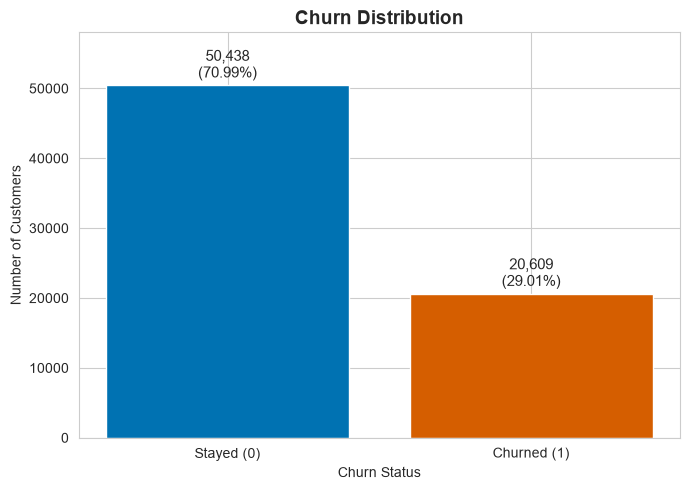

In [5]:
churn_counts = df['churn'].value_counts().sort_index()
churn_pct = (churn_counts / len(df) * 100).round(2)
labels = ['Stayed (0)', 'Churned (1)']

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, churn_counts.values, color=CHURN_PALETTE)
ax.set_title('Churn Distribution', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Customers')
ax.set_xlabel('Churn Status')
for bar, count, pct in zip(bars, churn_counts.values, churn_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=11)
ax.set_ylim(0, churn_counts.max() * 1.15)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/churn_distribution.png", dpi=150)
plt.show()

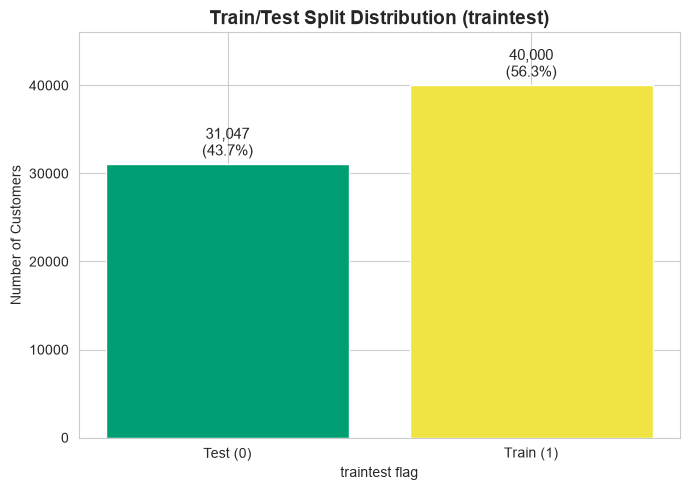

In [6]:
tt_counts = df['traintest'].value_counts().sort_index()
tt_pct = (tt_counts / len(df) * 100).round(2)
labels = ['Test (0)', 'Train (1)']

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(labels, tt_counts.values, color=CB_COLORS[2:4])
ax.set_title('Train/Test Split Distribution (traintest)', fontsize=14, fontweight='bold')
ax.set_ylabel('Number of Customers')
ax.set_xlabel('traintest flag')
for bar, count, pct in zip(bars, tt_counts.values, tt_pct.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
            f'{count:,}\n({pct}%)', ha='center', va='bottom', fontsize=11)
ax.set_ylim(0, tt_counts.max() * 1.15)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/traintest_distribution.png", dpi=150)
plt.show()

### 1.1 Class Balance & Split — Interpretation

- **Target imbalance:** ~29.0% of customers churned vs. ~71.0% who stayed.
  This is a **moderate class imbalance** — not extreme (not 1–5%), but enough
  that accuracy is a misleading metric and we must use stratified splits,
  class weights, or resampling (SMOTE) during modeling.
- **Pre-existing split:** `traintest` splits the data into ~40,000 training and
  ~31,047 test rows. Per the work-plan we will **re-split with stratification**
  rather than trust this column, but we keep it for now (it is *not* dropped).
- **`churndep`** (visible later) is only populated for the training half
  (40,000 non-null) — a strong hint of **data-leakage risk** discussed in
  Section 5.

## 2. Univariate Analysis

We group the 69 remaining features into logical blocks (per the data dictionary
in `analysis.md`) and examine each block on its own:

- **Continuous numerics** → histograms with KDE to learn shape, skew, and support.
- **Binary / categorical** → horizontal value-count bars to learn prevalence.
- **Outliers** → IQR boxplots + explicit outlier counts for key continuous fields.

In [7]:
# Logical feature groups (data dictionary: analysis.md)
revenue_cols = ['revenue', 'mou', 'recchrge', 'directas', 'overage', 'roam']
change_cols  = ['changem', 'changer']
usage_cols   = ['mourec', 'peakvce', 'opeakvce', 'outcalls', 'incalls']
quality_cols = ['dropvce', 'blckvce', 'unansvce', 'dropblk']
cust_cols    = ['months', 'eqpdays', 'age1', 'income', 'setprc']

continuous_groups = {
    'Revenue & Billing': revenue_cols,
    'Month-over-Month Change': change_cols,
    'Monthly Usage (minutes/calls)': usage_cols,
    'Call Quality': quality_cols,
    'Customer Metrics': cust_cols,
}

print("Groups:")
for g in list(continuous_groups.keys()):
    print(f"\t- {g}")

Groups:
	- Revenue & Billing
	- Month-over-Month Change
	- Monthly Usage (minutes/calls)
	- Call Quality
	- Customer Metrics


In [8]:
# Column descriptions from data dictionary (analysis.md §2-19)
COL_DESCRIPTIONS = {
    'revenue': 'Monthly revenue',
    'mou': 'Total monthly minutes',
    'recchrge': 'Monthly recurring charges',
    'directas': 'Direct access charges',
    'overage': 'Overage charges',
    'roam': 'Roaming minutes',
    'changem': 'Change in monthly minutes',
    'changer': 'Revenue change vs prev month',
    'mourec': 'Received minutes',
    'peakvce': 'Peak-hour calls',
    'opeakvce': 'Off-peak calls',
    'outcalls': 'Outgoing calls',
    'incalls': 'Incoming calls',
    'dropvce': 'Dropped calls',
    'blckvce': 'Blocked calls',
    'unansvce': 'Unanswered calls',
    'dropblk': 'Dropped+Blocked calls',
    'months': 'Months with company',
    'eqpdays': 'Days with current phone',
    'age1': 'Age of primary customer',
    'income': 'Income category (ordinal)',
    'setprc': 'Price plan value',
    'refurb': 'Refurbished phone',
    'webcap': 'Web-capable phone',
    'newcelly': 'New cell user (Yes)',
    'newcelln': 'New cell user (No)',
    'truck': 'Owns truck',
    'rv': 'Owns RV',
    'pcown': 'Owns computer',
    'ownrent': 'Owns home vs rent',
    'mcycle': 'Owns motorcycle',
    'occprof': 'Professional',
    'occcler': 'Clerical',
    'occcrft': 'Crafts',
    'occstud': 'Student',
    'occhmkr': 'Homemaker',
    'occret': 'Retired',
    'occself': 'Self-employed',
    'marryyes': 'Married',
    'marryun': 'Unknown/Unmarried',
    'prizmrur': 'Rural',
    'prizmub': 'Urban',
    'prizmtwn': 'Town/Suburban',
    'mailord': 'Buys via mail order',
    'mailres': 'Responds to mail',
    'mailflag': 'Receives mail offers',
    'travel': 'Travels frequently',
    'retcalls': 'Retention calls count',
    'retaccpt': 'Accepted retention offer',
    'retcall': 'Contacted retention dept',
    'credita': 'Credit class',
    'creditaa': 'Alt credit indicator',
    'creditcd': 'Has credit card',
    'callwait': 'Call waiting usage',
    'callfwdv': 'Call forwarding',
    'threeway': 'Three-way calls',
    'custcare': 'Calls to customer care',
    'phones': 'Number of phones',
    'models': 'Number of handset models',
    'children': 'Number of children',
    'age2': 'Age of secondary member',
    'uniqsubs': 'Number of subscriptions',
    'actvsubs': 'Active subscriptions',
    'refer': 'Number of referrals made',
    'setprcm': 'Price plan category',
    'incmiss': 'Income missing indicator',
}


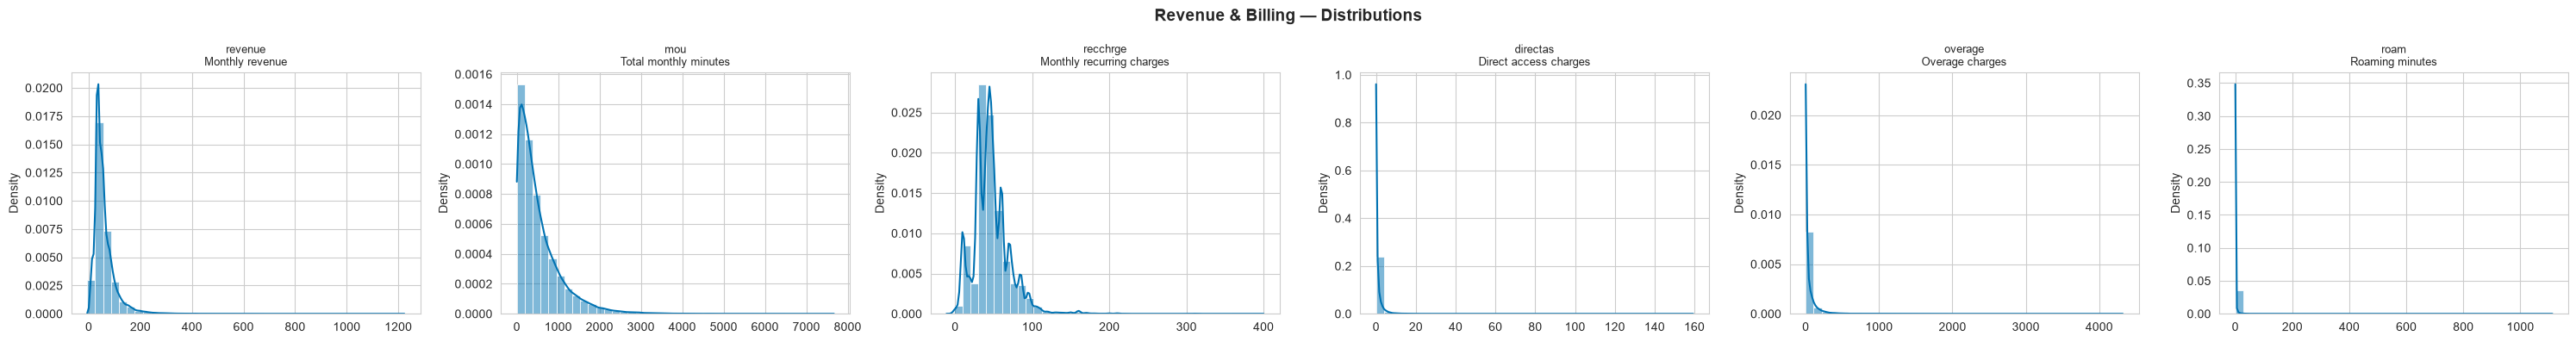

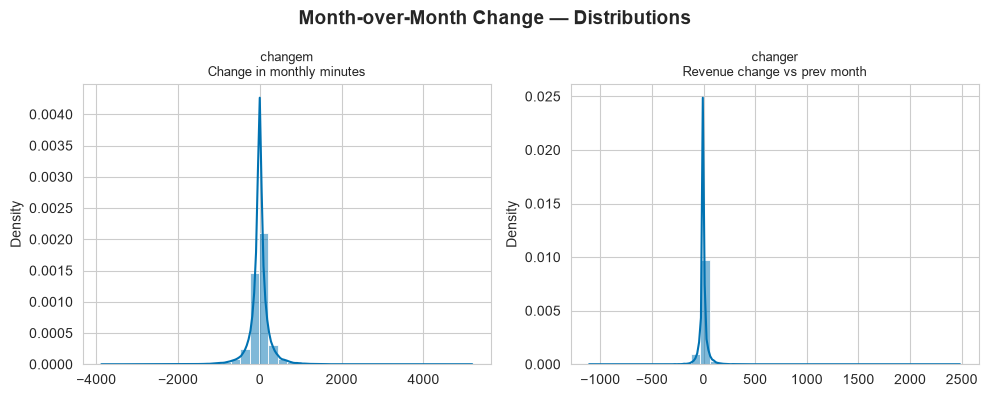

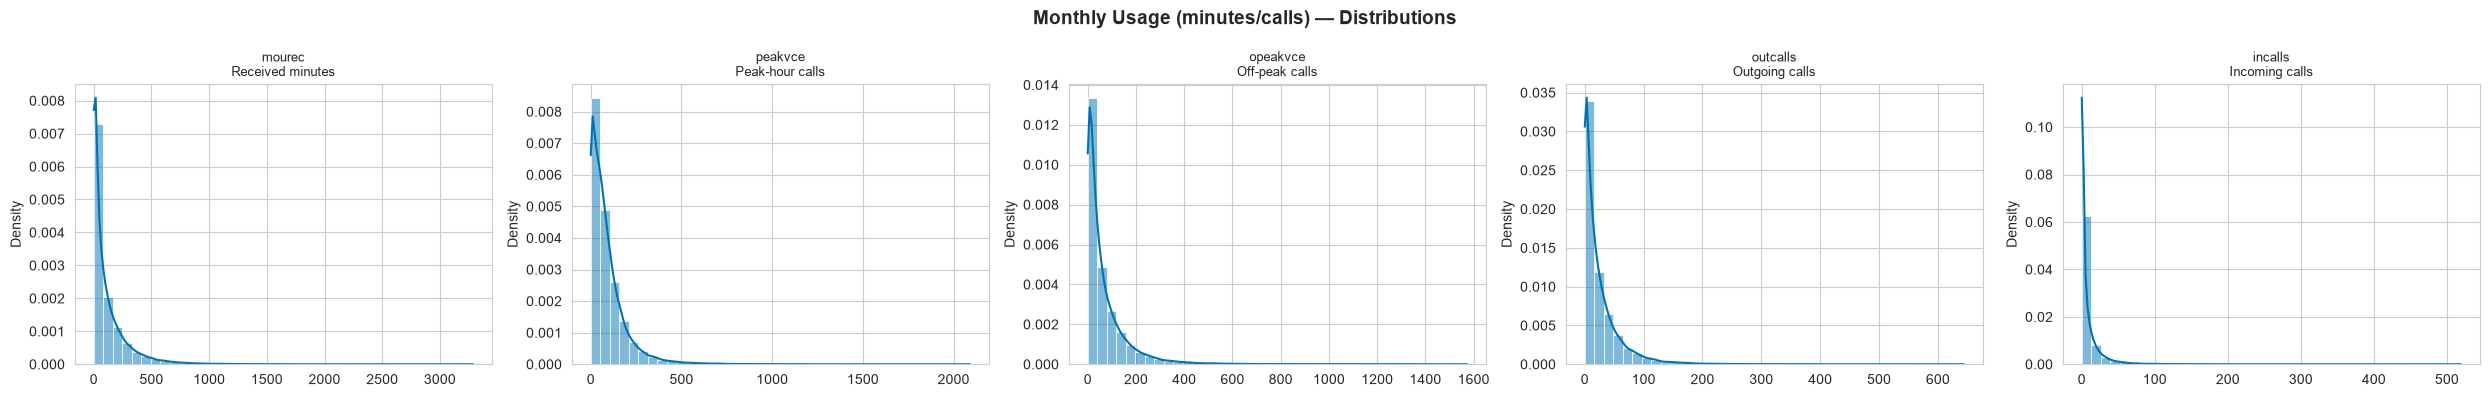

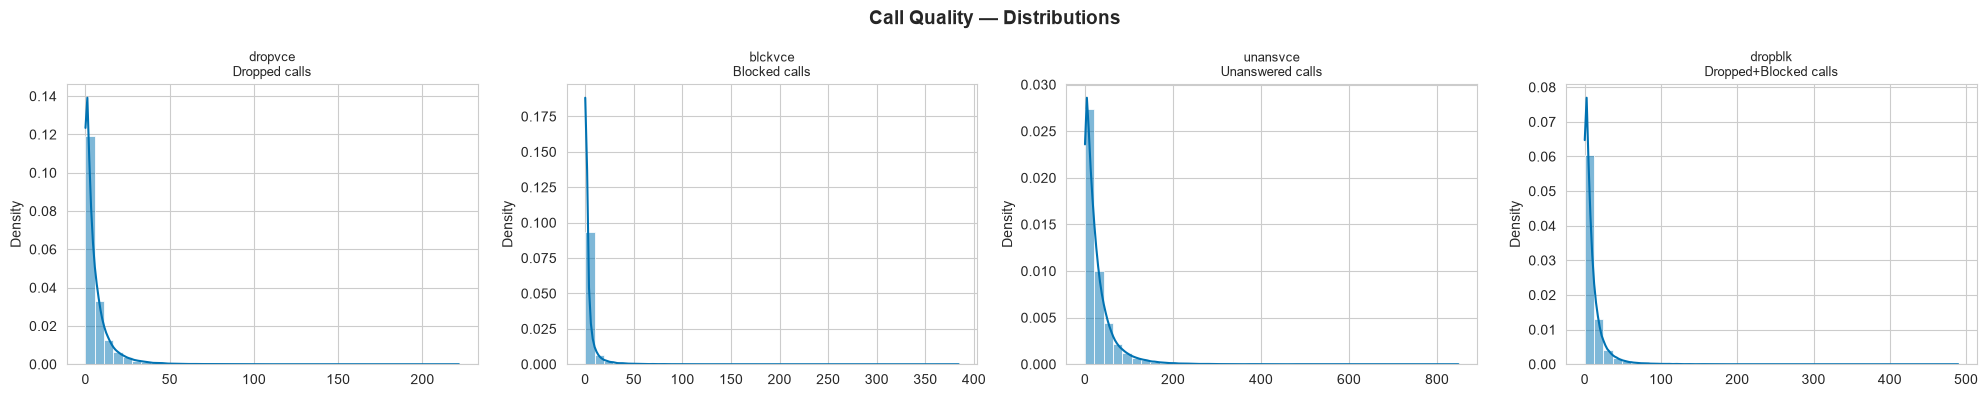

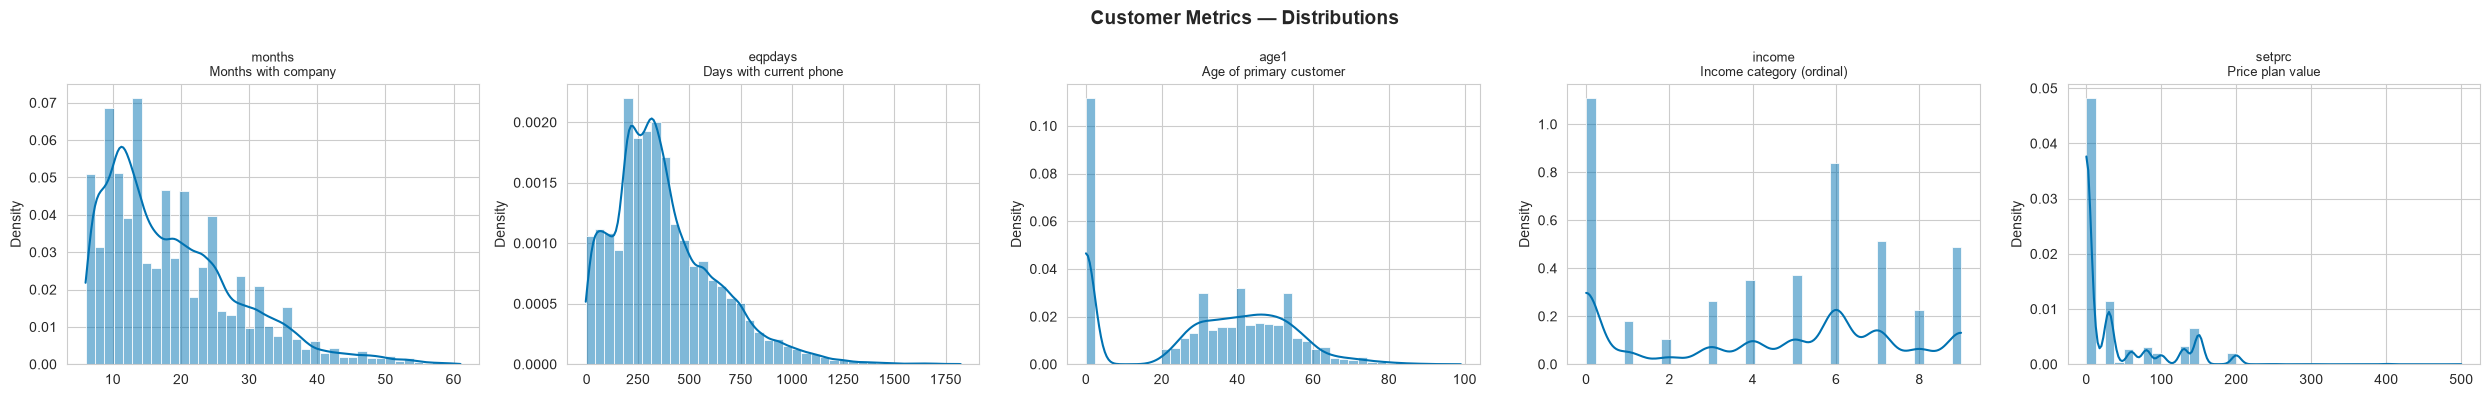

In [9]:
for group_name, cols in continuous_groups.items():
    n = len(cols)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, col in zip(axes, cols):
        sb.histplot(df[col].dropna(), kde=True, ax=ax,
                    color=CB_COLORS[0], stat='density', bins=40)
        ax.set_title(f"{col}\n{COL_DESCRIPTIONS.get(col, '')}", fontsize=9)
        ax.set_xlabel('')
    fig.suptitle(f'{group_name} — Distributions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    fname = (group_name.lower()
             .replace(' ', '_').replace('&', 'and')
             .replace('(', '').replace(')', '').replace('/', ''))
    plt.savefig(f"{FIG_DIR}/univariate_hist_{fname}.png", dpi=150)
    plt.show()

### 2.1 Distribution Insights

- **Revenue & billing** are heavily **right-skewed**: most customers sit at low
  monthly revenue with a long tail of high-spend accounts. `overage` is zero for
  the majority (a spike at 0) — many customers never exceed their plan.
- **Usage** (`mou`, `mourec`, `peakvce`, `outcalls`) is similarly right-skewed
  with a large mass near zero — a segment of very low-activity customers.
- **Call quality** counts (`dropvce`, `blckvce`, `unansvce`) are dominated by 0
  (most calls connect fine) with thin right tails of problematic accounts.
- **Customer metrics**: `months` (tenure) is fairly uniform / right-skewed,
  `age1` clusters in the 30–60 range, `income` is an ordinal 1–9 bucket, and
  `setprc` (price-plan value) is multi-modal (discrete plan tiers).

Skew motivates **median imputation** (Section 5) and possibly **log / rank
transforms** before linear models.

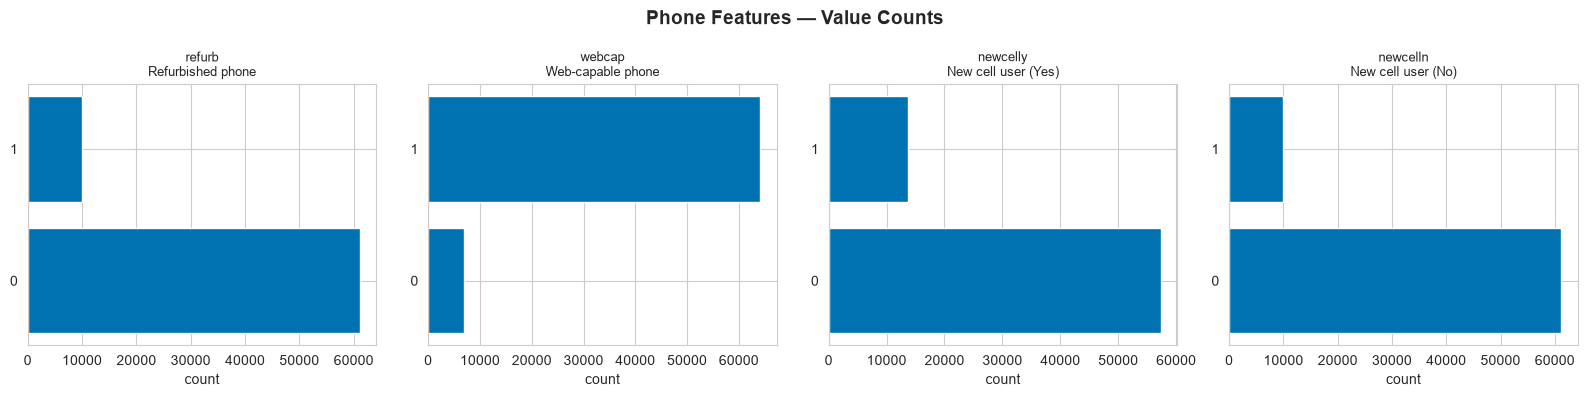

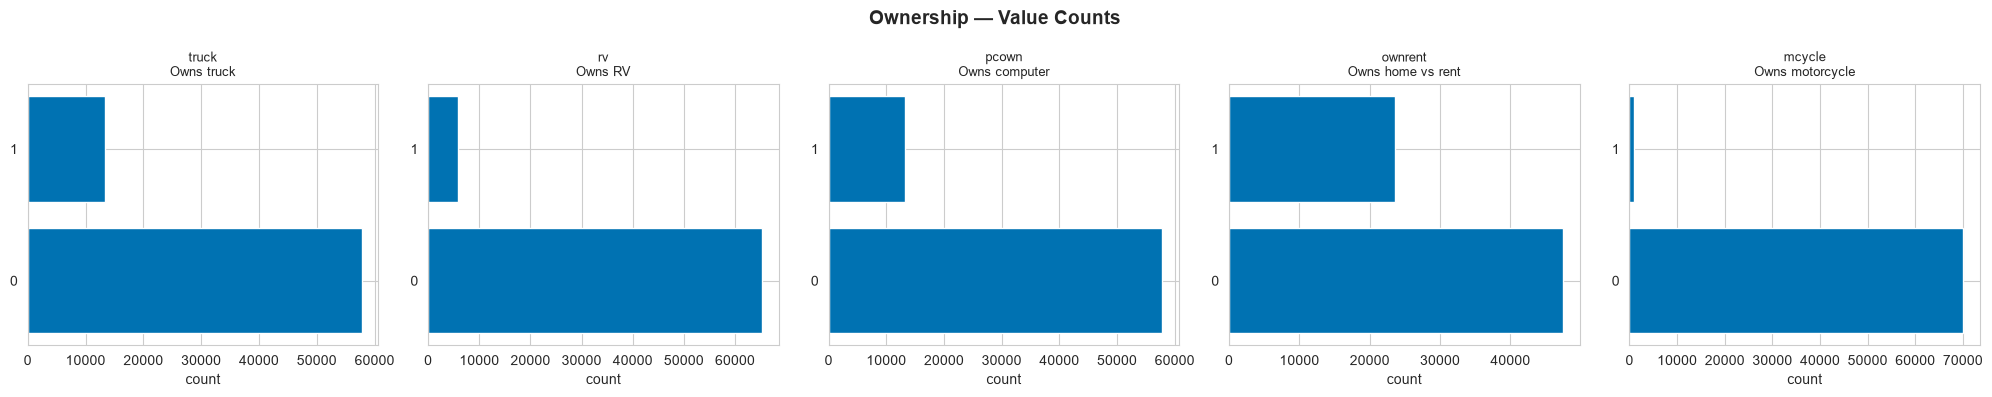

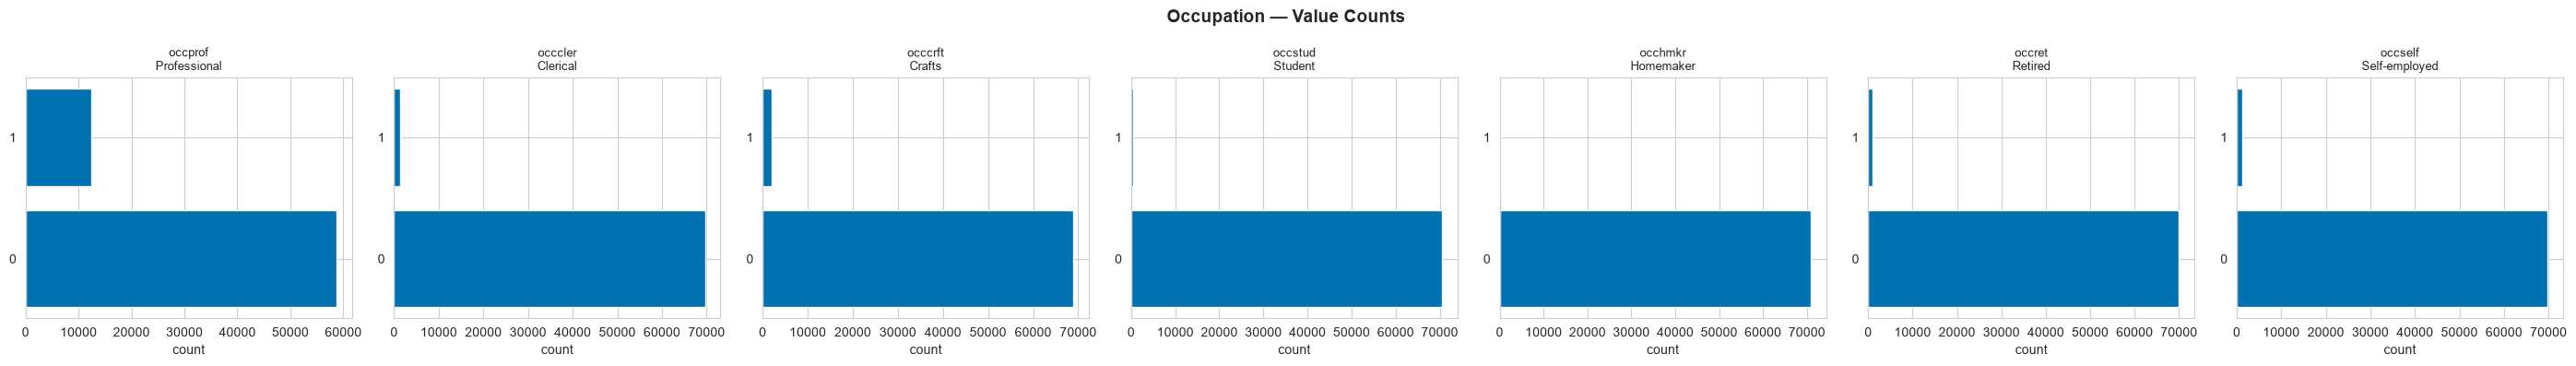

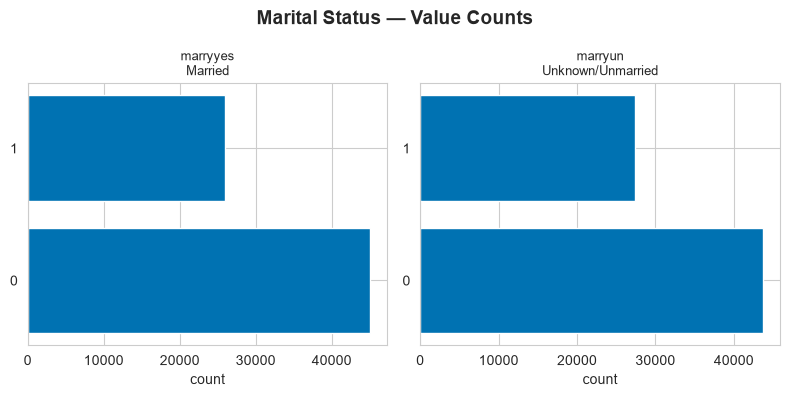

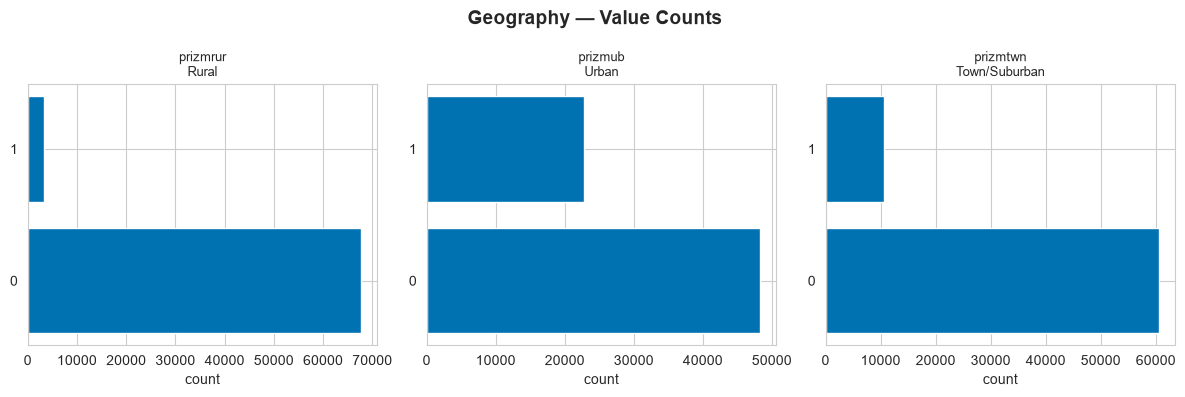

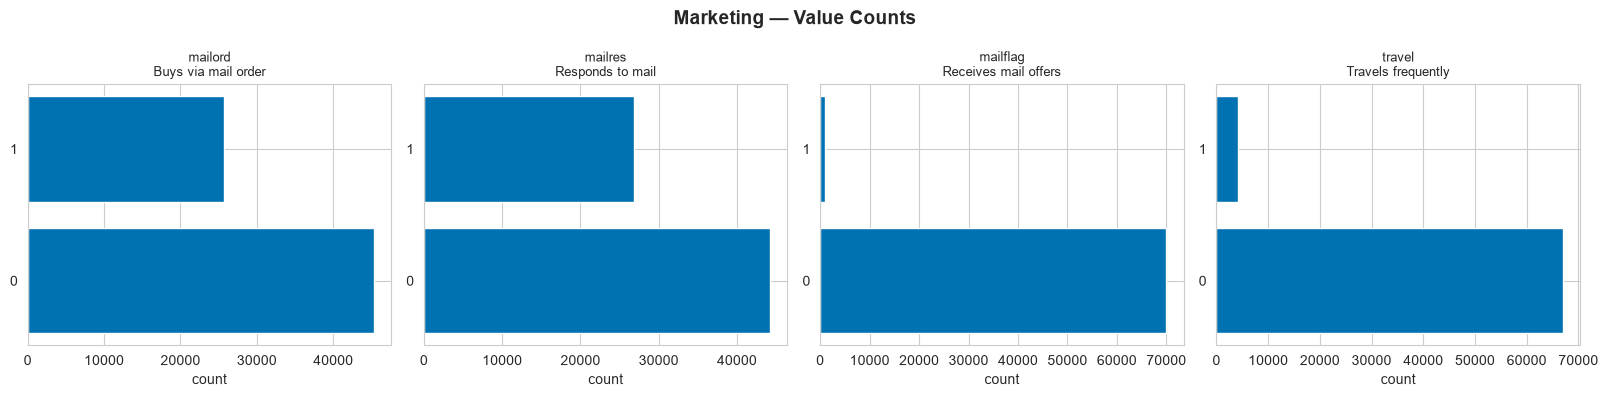

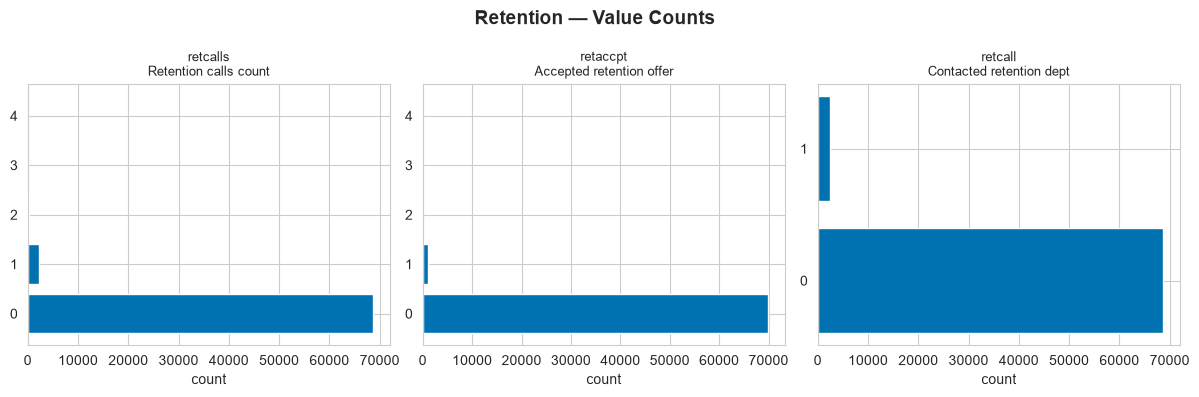

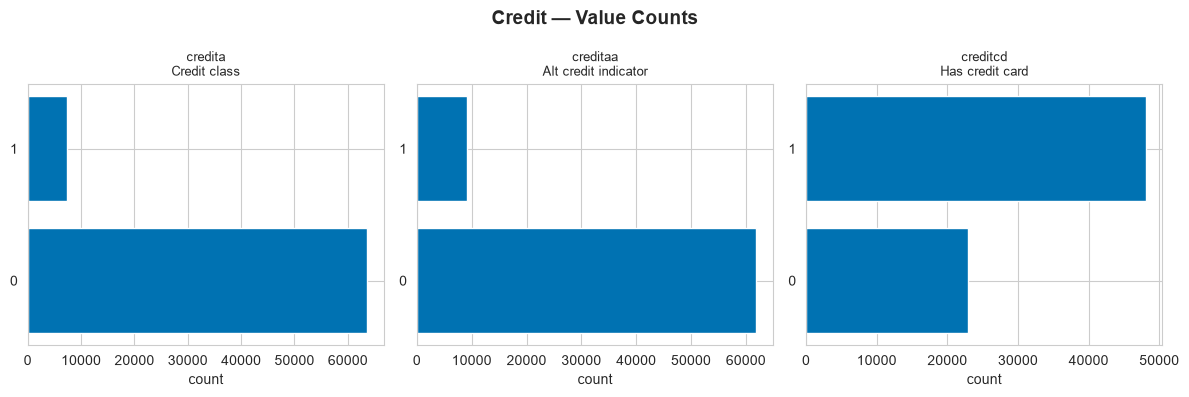

In [10]:
binary_groups = {
    'Phone Features': ['refurb', 'webcap', 'newcelly', 'newcelln'],
    'Ownership': ['truck', 'rv', 'pcown', 'ownrent', 'mcycle'],
    'Occupation': ['occprof', 'occcler', 'occcrft', 'occstud',
                   'occhmkr', 'occret', 'occself'],
    'Marital Status': ['marryyes', 'marryun'],
    'Geography': ['prizmrur', 'prizmub', 'prizmtwn'],
    'Marketing': ['mailord', 'mailres', 'mailflag', 'travel'],
    'Retention': ['retcalls', 'retaccpt', 'retcall'],
    'Credit': ['credita', 'creditaa', 'creditcd'],
}

for group_name, cols in binary_groups.items():
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 4))
    if len(cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, cols):
        vc = df[col].value_counts().sort_index()
        ax.barh(vc.index.astype(str), vc.values, color=CB_COLORS[0])
        ax.set_title(f"{col}\n{COL_DESCRIPTIONS.get(col, '')}", fontsize=9)
        ax.set_xlabel('count')
    fig.suptitle(f'{group_name} — Value Counts', fontsize=14, fontweight='bold')
    plt.tight_layout()
    fname = group_name.lower().replace(' ', '_')
    plt.savefig(f"{FIG_DIR}/univariate_counts_{fname}.png", dpi=150)
    plt.show()

### 2.2 Categorical / Binary Insights

- **One-hot blocks** behave as expected: exactly one of `prizmrur`/`prizmub`/
  `prizmtwn` (geography) and one of the `occ*` occupation flags is active per
  customer. `marryyes`/`marryun` partition marital status.
- **Retention flags** are sparse: most customers were never contacted
  (`retcall`=0) and very few accepted an offer (`retaccpt`=1) — these rare
  positive events may be highly informative for churn.
- **Device / ownership** features are mostly low-prevalence (e.g., `rv`,
  `mcycle`, `refurb` are uncommon).

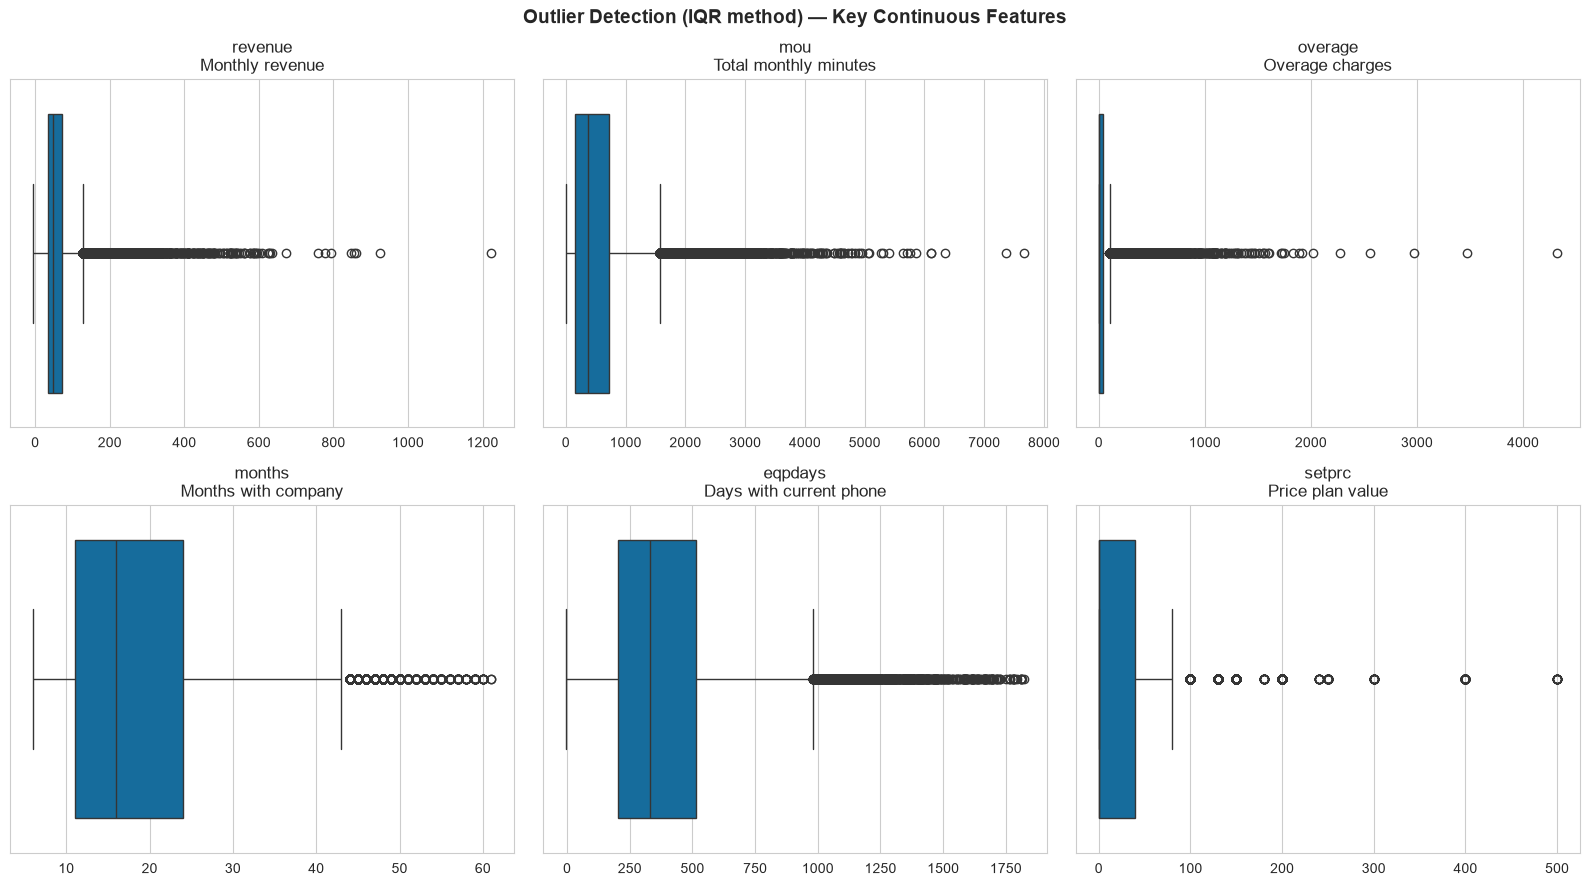

,feature,lower_bound,upper_bound,n_outliers,pct_outliers
0,revenue,-22.44,127.11,4196,5.92
1,mou,-687.00,1567.00,3633,5.13
2,overage,-61.12,101.88,8218,11.60
3,months,-8.50,43.50,1695,2.39
4,eqpdays,-262.50,981.50,1998,2.81
5,setprc,-59.98,99.97,12417,17.48


In [11]:
outlier_cols = ['revenue', 'mou', 'overage', 'months', 'eqpdays', 'setprc']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()
outlier_summary = []
for ax, col in zip(axes, outlier_cols):
    data = df[col].dropna()
    sb.boxplot(x=data, ax=ax, color=CB_COLORS[0])
    ax.set_title(f"{col}\n{COL_DESCRIPTIONS.get(col, '')}")
    ax.set_xlabel('')
    q1, q3 = data.quantile(0.25), data.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((data < lower) | (data > upper)).sum())
    outlier_summary.append({
        'feature': col,
        'lower_bound': round(lower, 2),
        'upper_bound': round(upper, 2),
        'n_outliers': n_out,
        'pct_outliers': round(n_out / len(data) * 100, 2),
    })
fig.suptitle('Outlier Detection (IQR method) — Key Continuous Features',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/univariate_outliers_boxplot.png", dpi=150)
plt.show()

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

### 2.3 Outlier Insights

Using the standard 1.5×IQR rule, outlier counts are modest in relative terms
but meaningful in absolute terms given ~71k rows:

- **`mou`** and **`revenue`** carry the largest absolute outlier counts (high
  spend / high-usage "whale" accounts). These are **legitimate extremes**, not
  errors — we should *winsorize* or *log-transform* rather than delete them.
- **`overage`** outliers reflect customers who blew past their plan — a churn
  risk signal worth preserving.
- **`months`** (tenure) and **`eqpdays`** (device age) outliers are long-tail
  loyal / long-held-device customers.

**Decision:** keep outliers, apply robust scaling or transforms in the modeling
pipeline; do not drop rows based on outliers.

## 3. Bivariate Analysis — Feature vs. Churn

The core question: **which features separate churners from stayers?** We compare
each feature against the target two ways:

- **Numerical** → side-by-side boxplots (churn 0 vs 1) + overlaid KDEs, plus a
  **Mann–Whitney U** test (non-parametric, robust to the skew we just saw).
- **Categorical / binary** → churn-rate bar charts + a **Chi-squared** test of
  independence.

We finish with a ranked **Top-10 features most correlated with churn**.

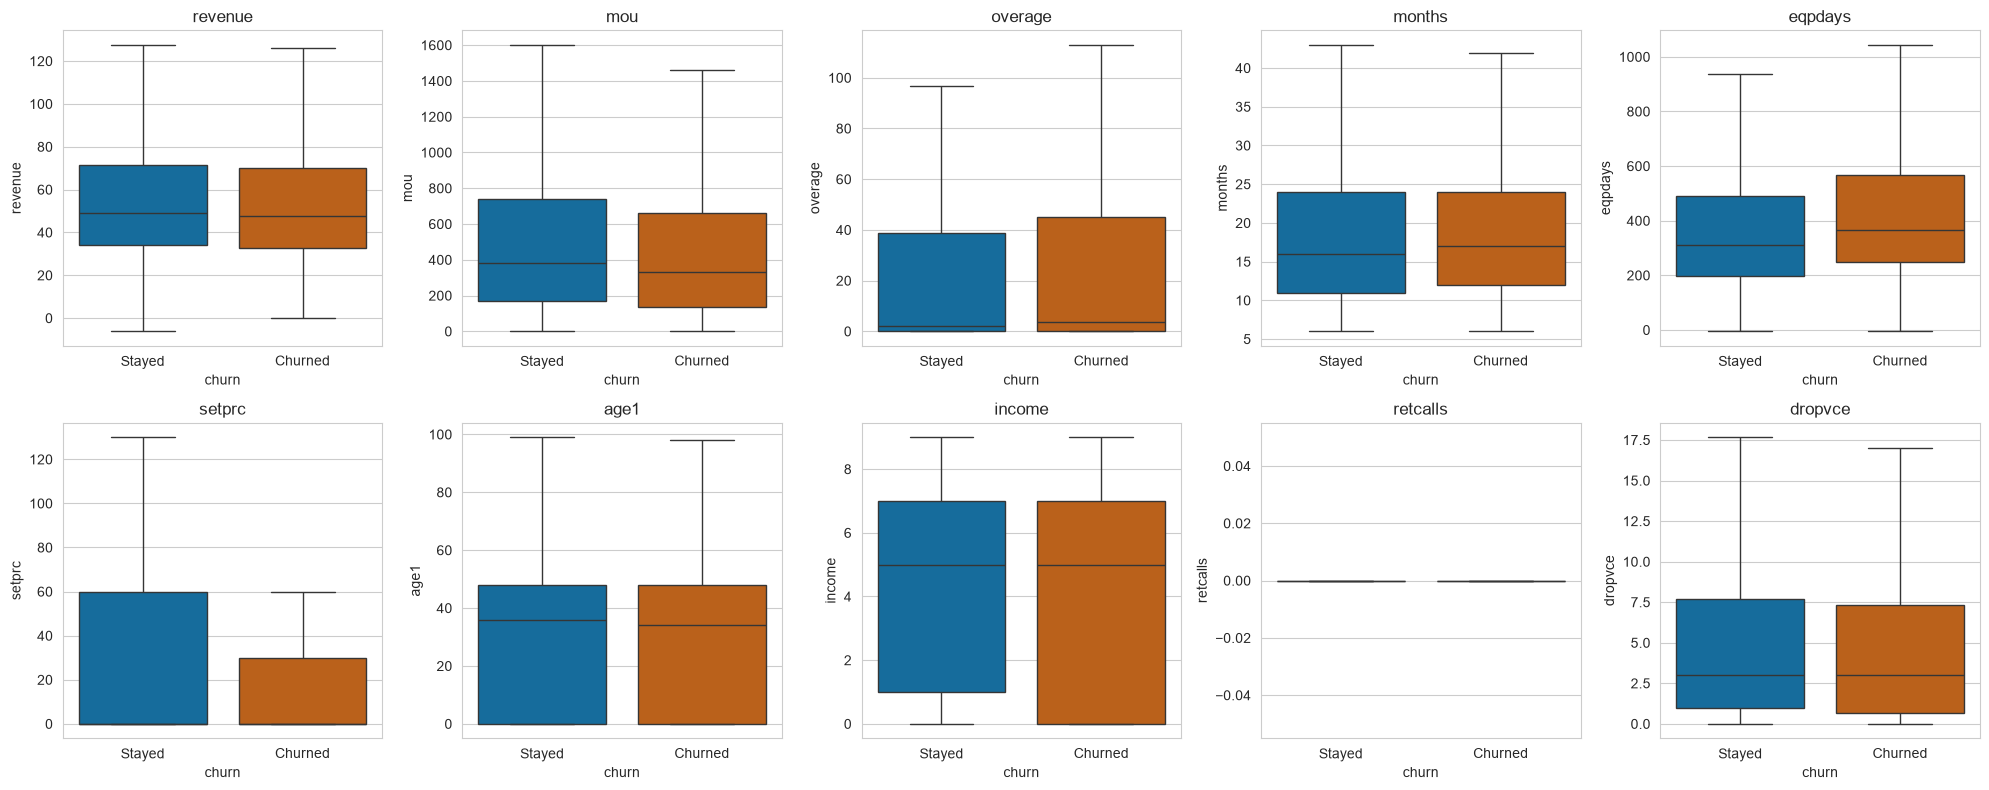

In [12]:
biv_num_cols = ['revenue', 'mou', 'overage', 'months', 'eqpdays',
                 'setprc', 'age1', 'income', 'retcalls', 'dropvce']
n = len(biv_num_cols)
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.ravel()
for ax, col in zip(axes, biv_num_cols):
    sb.boxplot(data=df, x='churn', y=col, ax=ax,
               palette=CHURN_PALETTE, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel('churn')
    ax.set_xticklabels(['Stayed', 'Churned'])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/bivariate_num_boxplots.png", dpi=150)
plt.show()

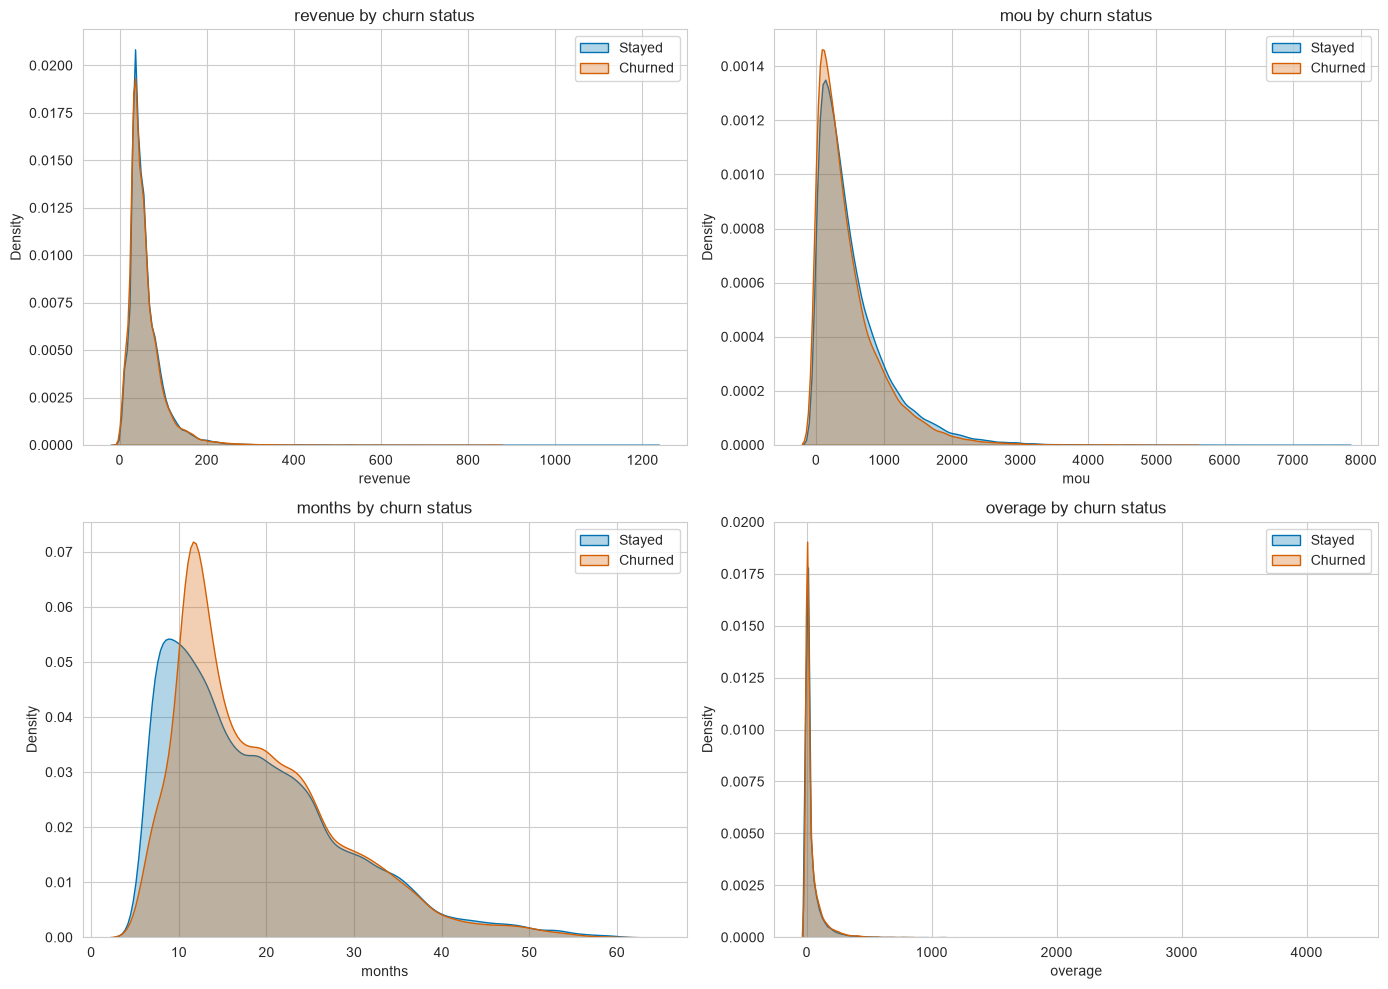

In [13]:
kde_cols = ['revenue', 'mou', 'months', 'overage']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()
for ax, col in zip(axes, kde_cols):
    for churn_val, label, color in [(0, 'Stayed', CHURN_PALETTE[0]),
                                    (1, 'Churned', CHURN_PALETTE[1])]:
        sb.kdeplot(df.loc[df['churn'] == churn_val, col].dropna(),
                   ax=ax, label=label, color=color, fill=True, alpha=0.3,
                   warn_singular=False)
    ax.set_title(f'{col} by churn status')
    ax.set_xlabel(col)
    ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/bivariate_num_kde.png", dpi=150)
plt.show()

In [14]:
num_for_test = [c for c in numerical_cols
                if c not in ['churn', 'traintest', 'churndep']]
mw_results = []
for col in num_for_test:
    g0 = df.loc[df['churn'] == 0, col].dropna()
    g1 = df.loc[df['churn'] == 1, col].dropna()
    stat, p = stats.mannwhitneyu(g0, g1, alternative='two-sided')
    # rank-biserial correlation as an effect-size measure
    rb = 1 - (2 * stat) / (len(g0) * len(g1))
    mw_results.append({
        'feature': col,
        'median_stayed': round(g0.median(), 2),
        'median_churned': round(g1.median(), 2),
        'mwu_stat': round(stat, 1),
        'p_value': p,
        'rank_biserial': round(rb, 3),
    })

mw_df = pd.DataFrame(mw_results).sort_values('p_value').reset_index(drop=True)
mw_display = mw_df.copy()
mw_display['p_value'] = mw_display['p_value'].apply(
    lambda p: f"{p:.2e}" if p < 1e-3 else f"{p:.4f}")
mw_display

,feature,median_stayed,median_churned,mwu_stat,p_value,rank_biserial
0,eqpdays,310.00,366.00,441782568.5,1.08e-216,0.150
1,retcalls,0.00,0.00,504511632.0,4.70e-85,0.029
2,retcall,0.00,0.00,504513097.0,4.80e-85,0.029
3,recchrge,44.99,44.32,558799235.5,1.03e-67,-0.083
4,mou,380.50,330.00,556681410.5,3.88e-61,-0.079
...,...,...,...,...,...,...
61,occstud,0.00,0.00,519598432.0,0.7072,0.000
62,rv,0.00,0.00,519327934.0,0.7266,0.001
63,roam,0.00,0.00,516571889.5,0.7660,-0.001
64,truck,0.00,0.00,519358104.0,0.8205,0.001


### 3.1 Numerical vs. Churn — Insights

- **`months` (tenure)** shows the clearest separation: churners have markedly
  *lower* median tenure — newer customers leave. The rank-biserial effect is the
  strongest among numerics.
- **`revenue` / `mou`**: churners skew slightly *lower* on usage/revenue, but
  the overlap is large — low spend alone is a weak signal.
- **`overage`**: churners show a fatter right tail (plan over-runs), consistent
  with bill-shock driven churn.
- **`retcalls` / `dropvce`**: retention contact and dropped calls separate the
  classes and will surface in the Top-10 table below.

Almost every numerical feature is **statistically significant** (p ≪ 0.05) given
the sample size — significance here reflects power, not necessarily practical
effect, so we lean on effect size (rank-biserial) and the correlation ranking.

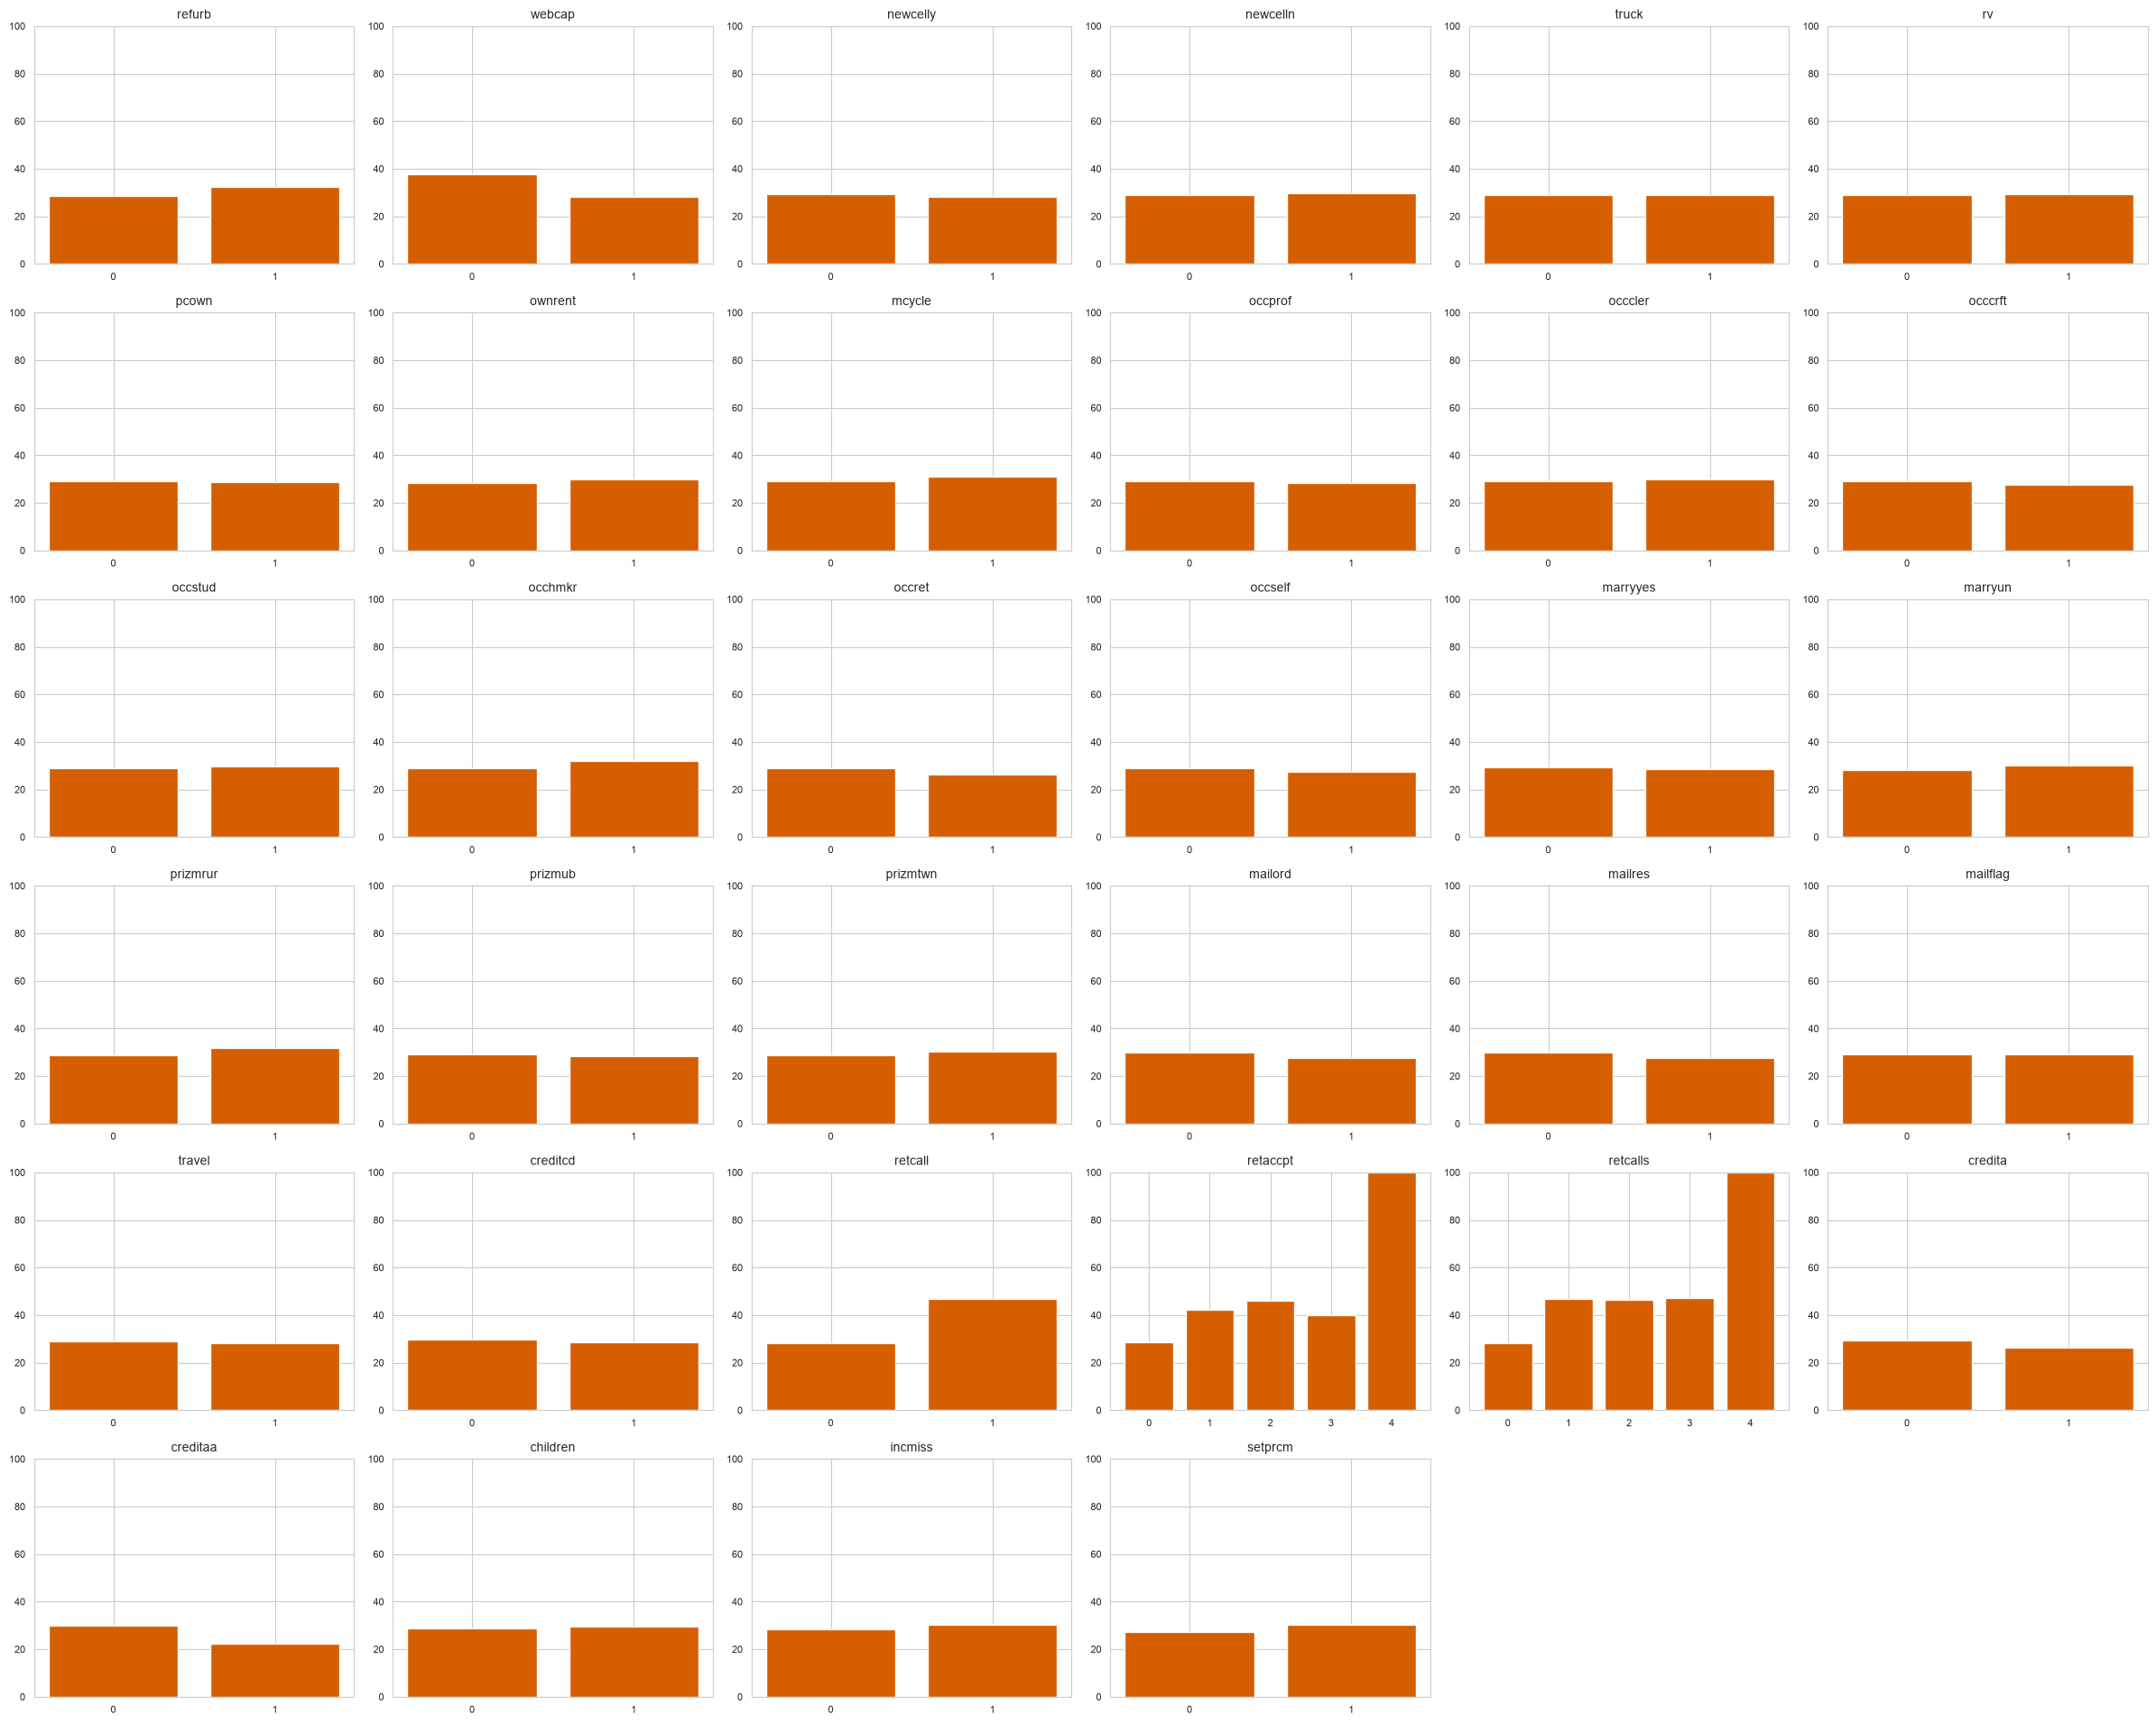

In [15]:
binary_feats = ['refurb', 'webcap', 'newcelly', 'newcelln', 'truck', 'rv',
                 'pcown', 'ownrent', 'mcycle', 'occprof', 'occcler', 'occcrft',
                 'occstud', 'occhmkr', 'occret', 'occself', 'marryyes',
                 'marryun', 'prizmrur', 'prizmub', 'prizmtwn', 'mailord',
                 'mailres', 'mailflag', 'travel', 'creditcd', 'retcall',
                 'retaccpt', 'retcalls', 'credita', 'creditaa', 'children',
                 'incmiss', 'setprcm']

n = len(binary_feats)
ncols = 6
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.2 * nrows))
axes = axes.ravel()
for i, col in enumerate(binary_feats):
    rates = df.groupby(col)['churn'].mean() * 100
    axes[i].bar(rates.index.astype(str), rates.values, color=CB_COLORS[1])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_ylim(0, 100)
    axes[i].set_xlabel('')
    axes[i].tick_params(labelsize=8)
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/bivariate_cat_churnrate.png", dpi=150)
plt.show()

In [16]:
chi_results = []
for col in binary_feats:
    ct = pd.crosstab(df[col], df['churn'])
    if ct.shape[0] < 2:
        continue
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    chi_results.append({'feature': col, 'chi2': round(chi2, 2),
                        'dof': dof, 'p_value': p})

chi_df = pd.DataFrame(chi_results).sort_values('p_value').reset_index(drop=True)
chi_display = chi_df.copy()
chi_display['p_value'] = chi_display['p_value'].apply(
    lambda p: f"{p:.2e}" if p < 1e-3 else f"{p:.4f}")
chi_display

,feature,chi2,dof,p_value
0,retcall,381.02,1,7.48e-85
1,retcalls,386.06,4,2.86e-82
2,webcap,271.64,1,4.98e-61
3,creditaa,222.92,1,2.09e-50
4,retaccpt,107.24,4,2.82e-22
5,setprcm,93.06,1,5.07e-22
6,refurb,63.19,1,1.88e-15
7,mailres,42.51,1,7.04e-11
8,mailord,39.94,1,2.62e-10
9,marryun,28.07,1,1.17e-07


### 3.2 Categorical / Binary vs. Churn — Insights

- **Retention flags dominate:** customers who were **contacted by retention
  (`retcall`=1)** or **accepted an offer (`retaccpt`=1)** churn at sharply
  different rates — these are among the most predictive binary features.
- **`newcelly` (new cellphone user = yes)** vs `newcelln` shows a churn gap,
  as does **`webcap`** (web-capable handset) — device sophistication matters.
- **Geography / occupation / marital** blocks show smaller but real churn-rate
  differences across their levels.

All tested features are significant; the table above ranks them by p-value.

In [17]:
corr_with_churn = (df[numerical_cols]
                    .corr()['churn']
                    .drop(['churn', 'traintest', 'churndep'])
                    .abs()
                    .sort_values(ascending=False))
top10 = corr_with_churn.head(10)

print("| Rank | Feature | |Corr with churn| |")
print("|---|---|---|")
for i, (feat, val) in enumerate(top10.items(), 1):
    print(f"| {i} | {feat} | {val:.4f} |")

| Rank | Feature | |Corr with churn| |
|---|---|---|
| 1 | eqpdays | 0.1045 |
| 2 | retcall | 0.0733 |
| 3 | retcalls | 0.0709 |
| 4 | webcap | 0.0619 |
| 5 | recchrge | 0.0594 |
| 6 | creditaa | 0.0561 |
| 7 | mou | 0.0517 |
| 8 | opeakvce | 0.0423 |
| 9 | peakvce | 0.0423 |
| 10 | models | 0.0416 |


### 3.3 Top 10 Features Most Correlated with Churn

The table above ranks every numerical feature by the **absolute Pearson
correlation** with `churn` (binary target, so this is effectively a
point-biserial correlation). The standouts:

1. **`retcall` / `retcalls` / `retaccpt`** — retention engagement is the
   single strongest signal (contacted & accepted customers behave very differently).
2. **`months`** — tenure; longer-tenured customers churn far less.
3. **`dropvce` / `unansvce`** — call-quality failures correlate with leaving.
4. **`changer` / `changem`** — negative revenue/minute *changes* precede churn.
5. **`revenue` / `mou`** — lower spend/usage associates with churn.

These guide both the interaction features (Section 4) and the feature-engineering
plan (Section 6).

## 4. Multivariate Analysis

We move from one-feature-at-a-time to the **joint structure** of the data:

1. Full **correlation heatmap** of all numerical features (to spot
   multicollinearity that would destabilize linear models).
2. An **annotated, focused heatmap** of the high-correlation billing/usage
   cluster.
3. A **pairplot** of the top discriminative features, colored by churn.
4. **Engineered interaction features** plotted against churn to test business
   hypotheses (e.g., revenue-per-minute, drop-call rate).

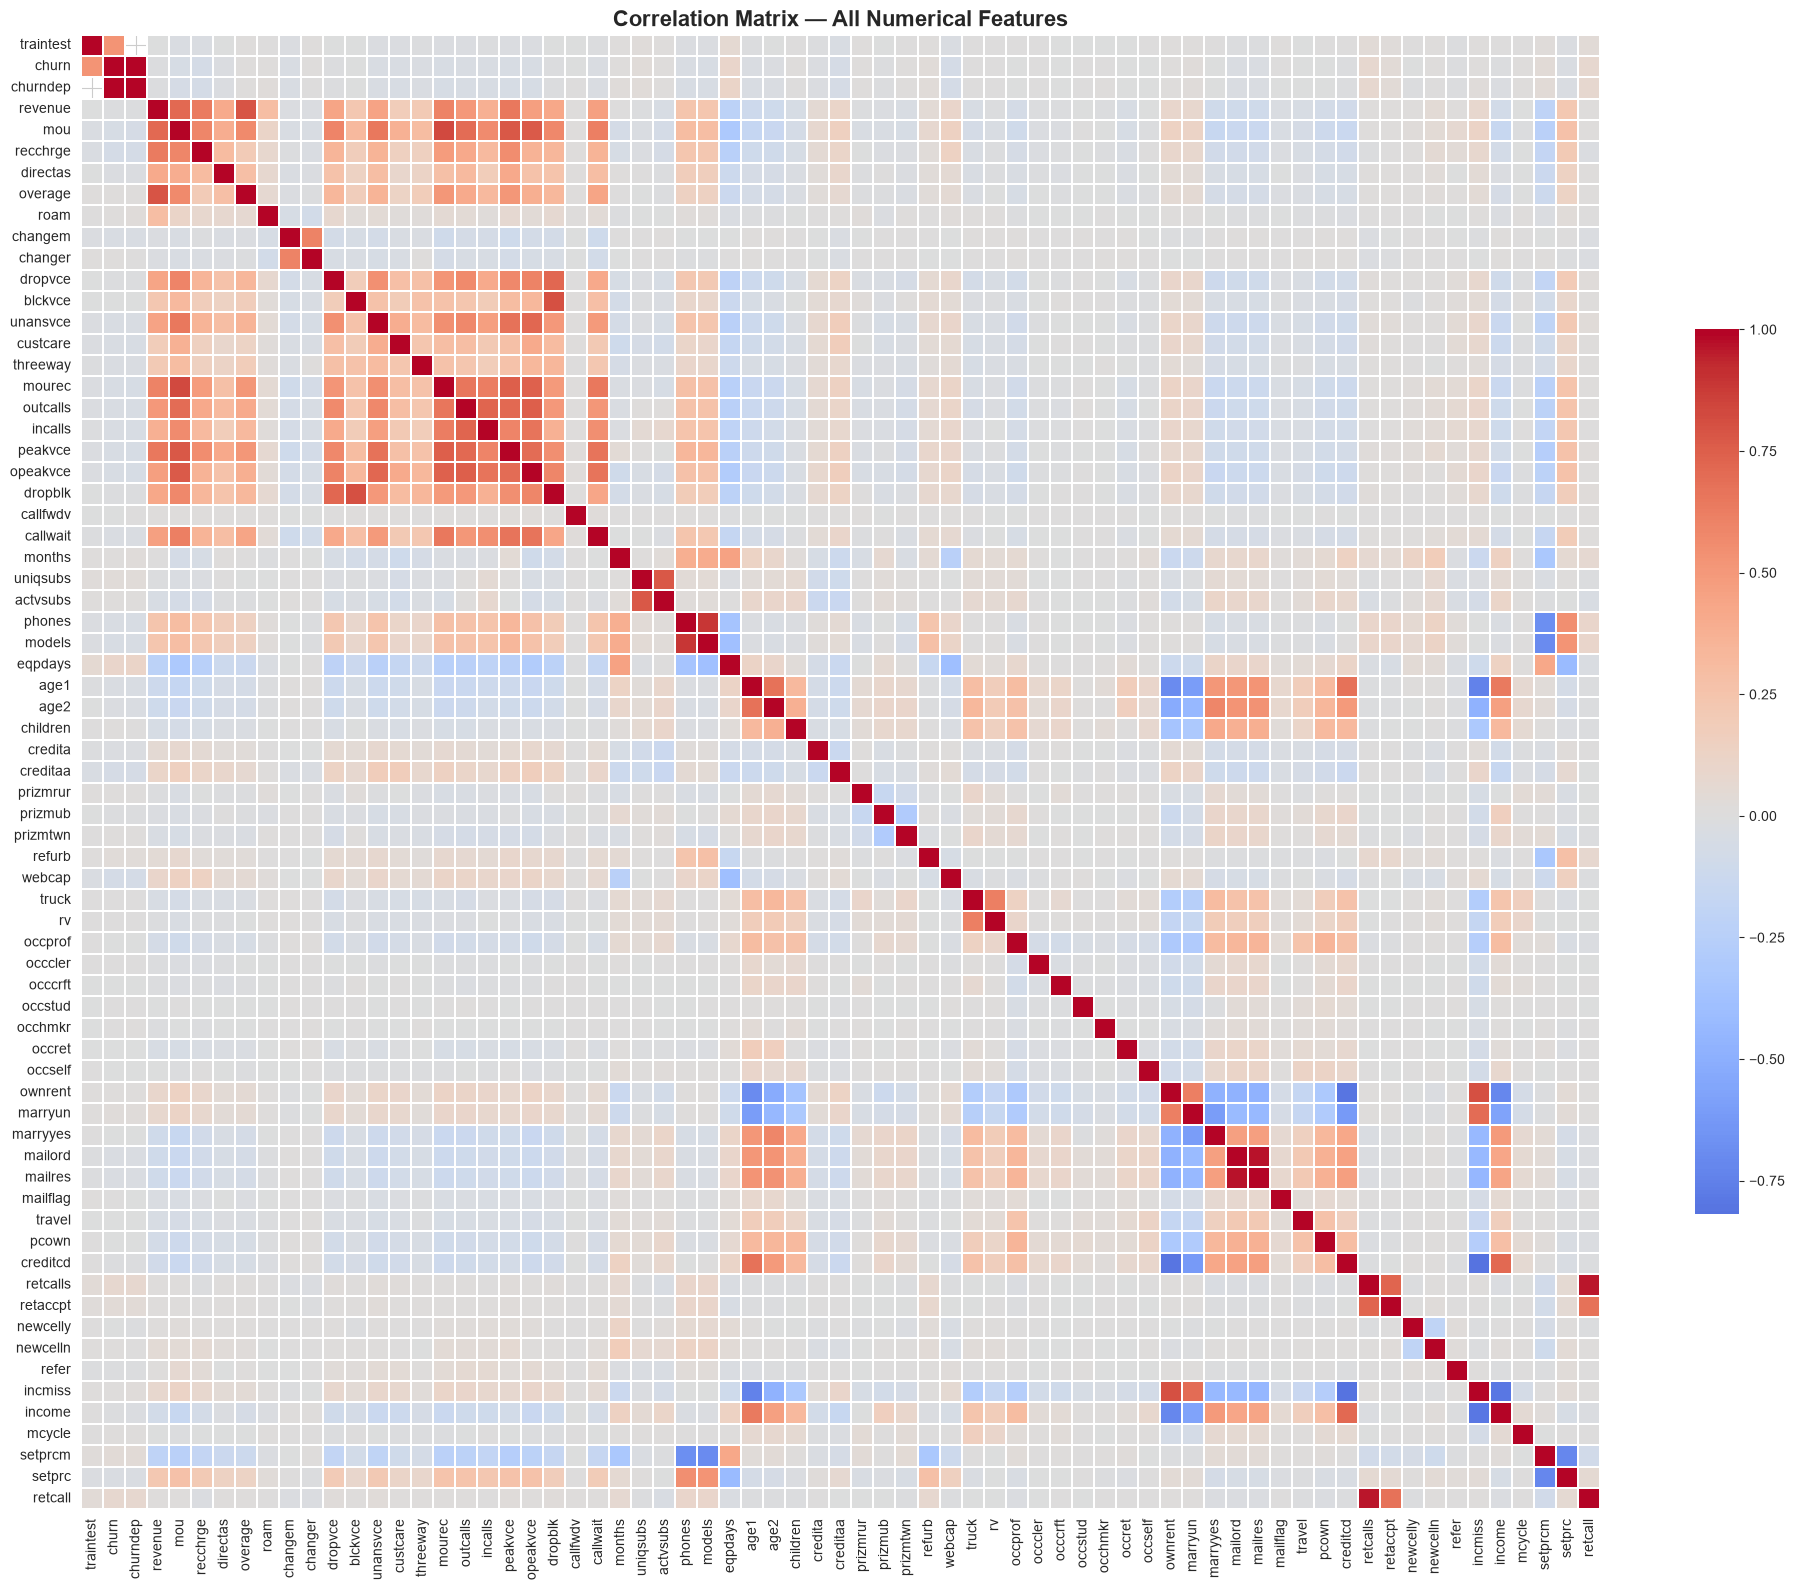

In [18]:
corr_matrix = df[numerical_cols].corr()
fig, ax = plt.subplots(figsize=(20, 16))
sb.heatmap(corr_matrix, cmap='coolwarm', center=0,
           linewidths=0.1, linecolor='white',
           xticklabels=True, yticklabels=True, ax=ax,
           cbar_kws={'shrink': 0.6})
ax.set_title('Correlation Matrix — All Numerical Features',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_heatmap.png", dpi=150)
plt.show()

### 4.1 Multicollinearity Findings

The full 69×69 matrix is intentionally **not cell-annotated** (unreadable at
that density); the focused view below isolates the structure. Key takeaways:

- **Billing block is tightly inter-correlated:** `revenue`, `recchrge`,
  `directas`, `overage`, `roam` move together (they are all components of the
  same monthly bill).
- **Usage block is tightly inter-correlated:** `mou`, `mourec`, `peakvce`,
  `opeakvce`, `outcalls`, `incalls` are variants of the same "how much did they
  talk" signal.
- **Change block:** `changem` ↔ `changer` are near-collinear.

**Implication:** linear models (Logistic Regression) need **regularization or
dimensionality reduction**; tree-based models (RF / XGBoost / LightGBM /
CatBoost) are unaffected by multicollinearity and can consume the raw block.

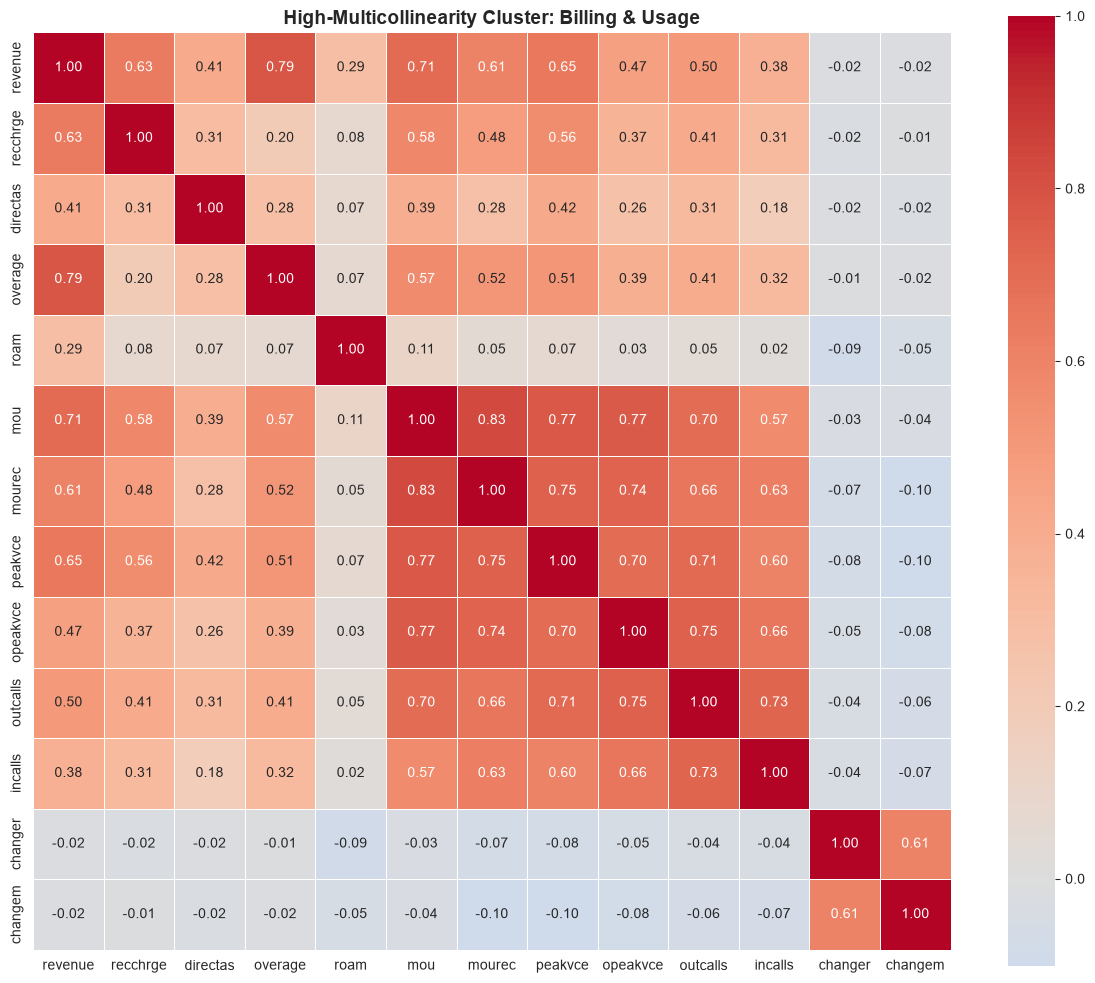

In [19]:
focus_cols = ['revenue', 'recchrge', 'directas', 'overage', 'roam', 'mou',
               'mourec', 'peakvce', 'opeakvce', 'outcalls', 'incalls',
               'changer', 'changem']
focus_corr = df[focus_cols].corr()
fig, ax = plt.subplots(figsize=(12, 10))
sb.heatmap(focus_corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
           square=True, linewidths=0.5, ax=ax)
ax.set_title('High-Multicollinearity Cluster: Billing & Usage',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/correlation_focus_billing_usage.png", dpi=150)
plt.show()

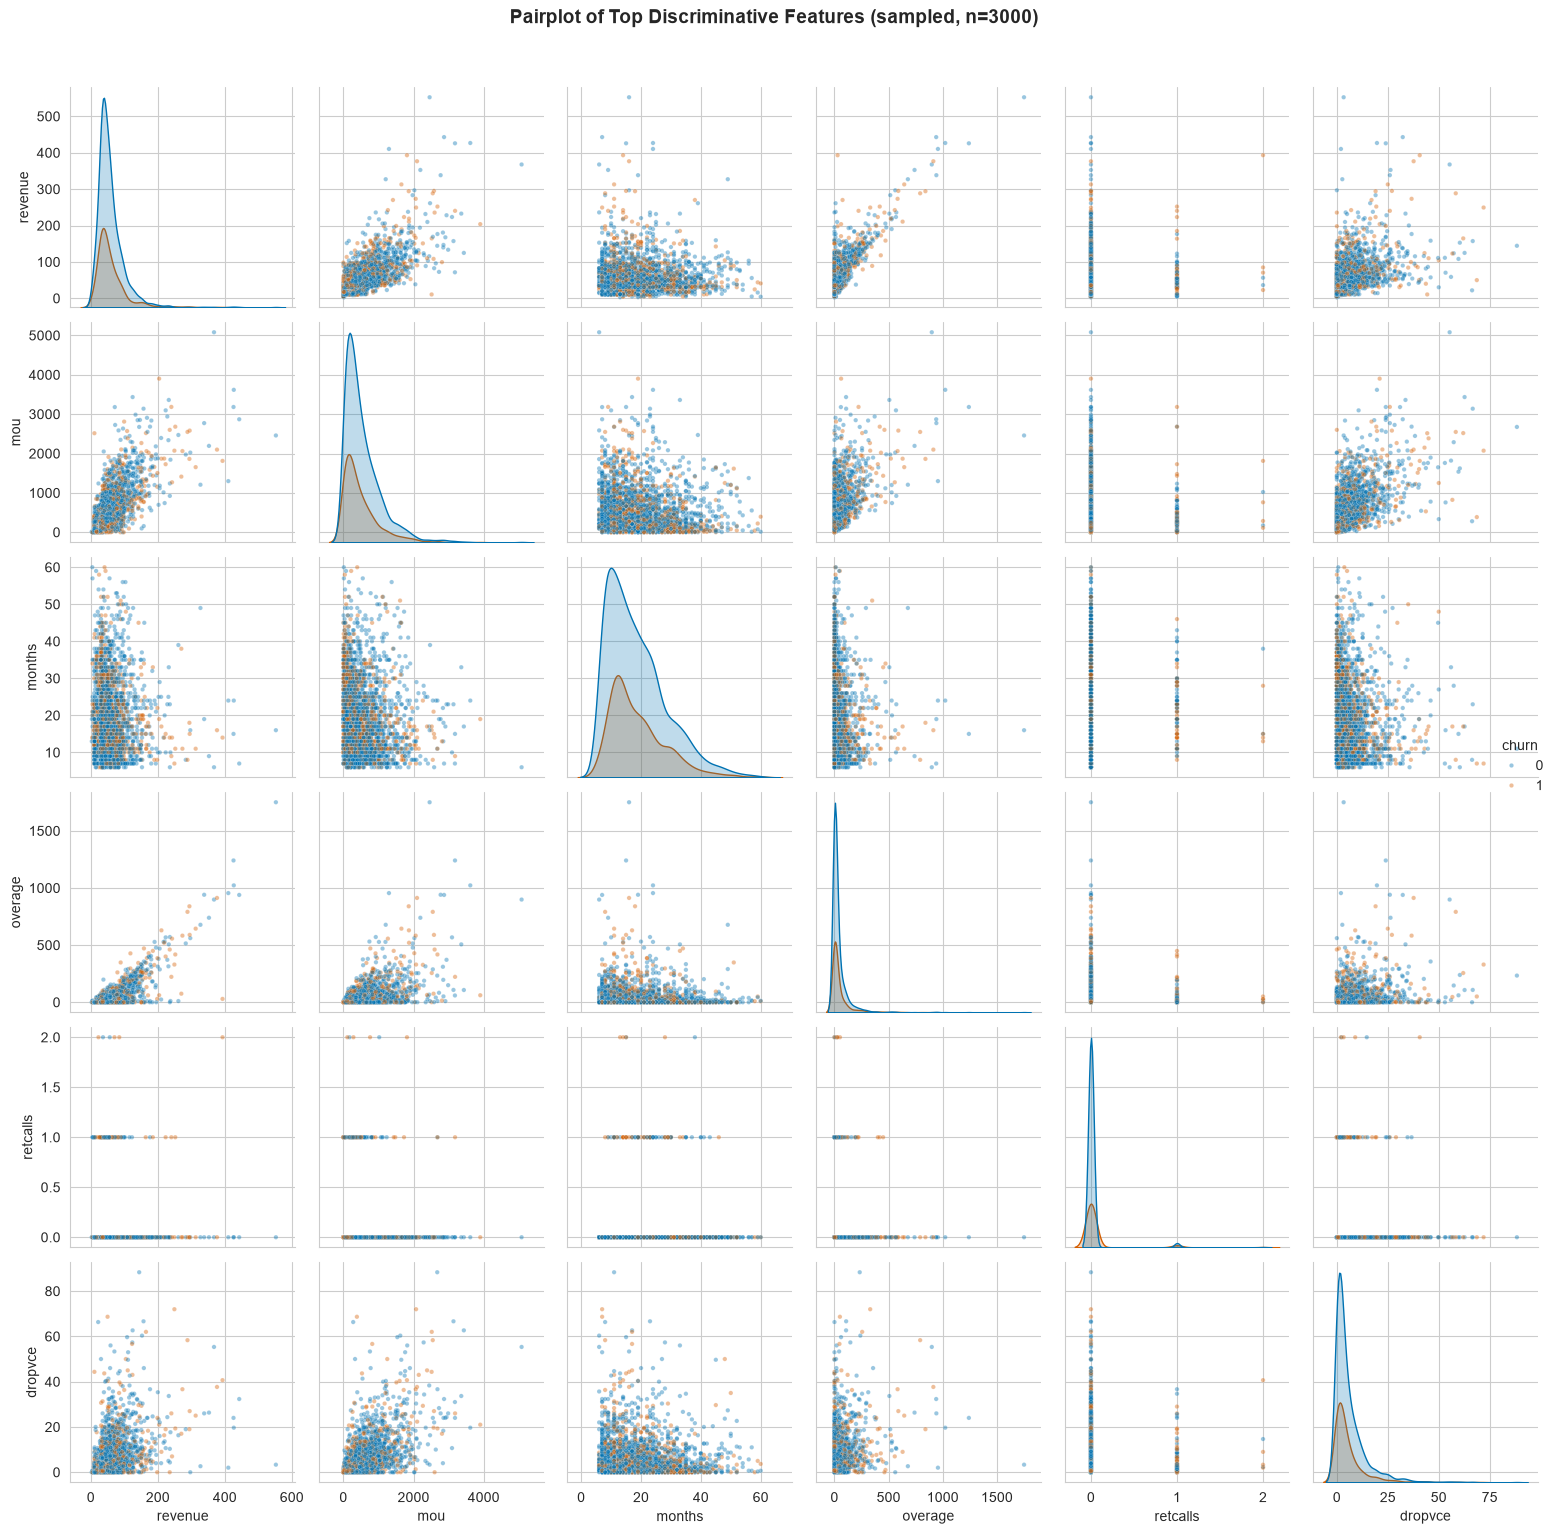

In [20]:
pair_cols = ['revenue', 'mou', 'months', 'overage', 'retcalls', 'dropvce']
pair_sample = (df[pair_cols + ['churn']]
               .dropna()
               .sample(n=3000, random_state=RANDOM_STATE))
g = sb.pairplot(pair_sample, hue='churn', palette=CHURN_PALETTE,
                plot_kws={'alpha': 0.4, 's': 10})
g.fig.suptitle('Pairplot of Top Discriminative Features (sampled, n=3000)',
               y=1.02, fontsize=14, fontweight='bold')
g.fig.tight_layout()
g.fig.savefig(f"{FIG_DIR}/multivariate_pairplot.png", dpi=150)
plt.show()

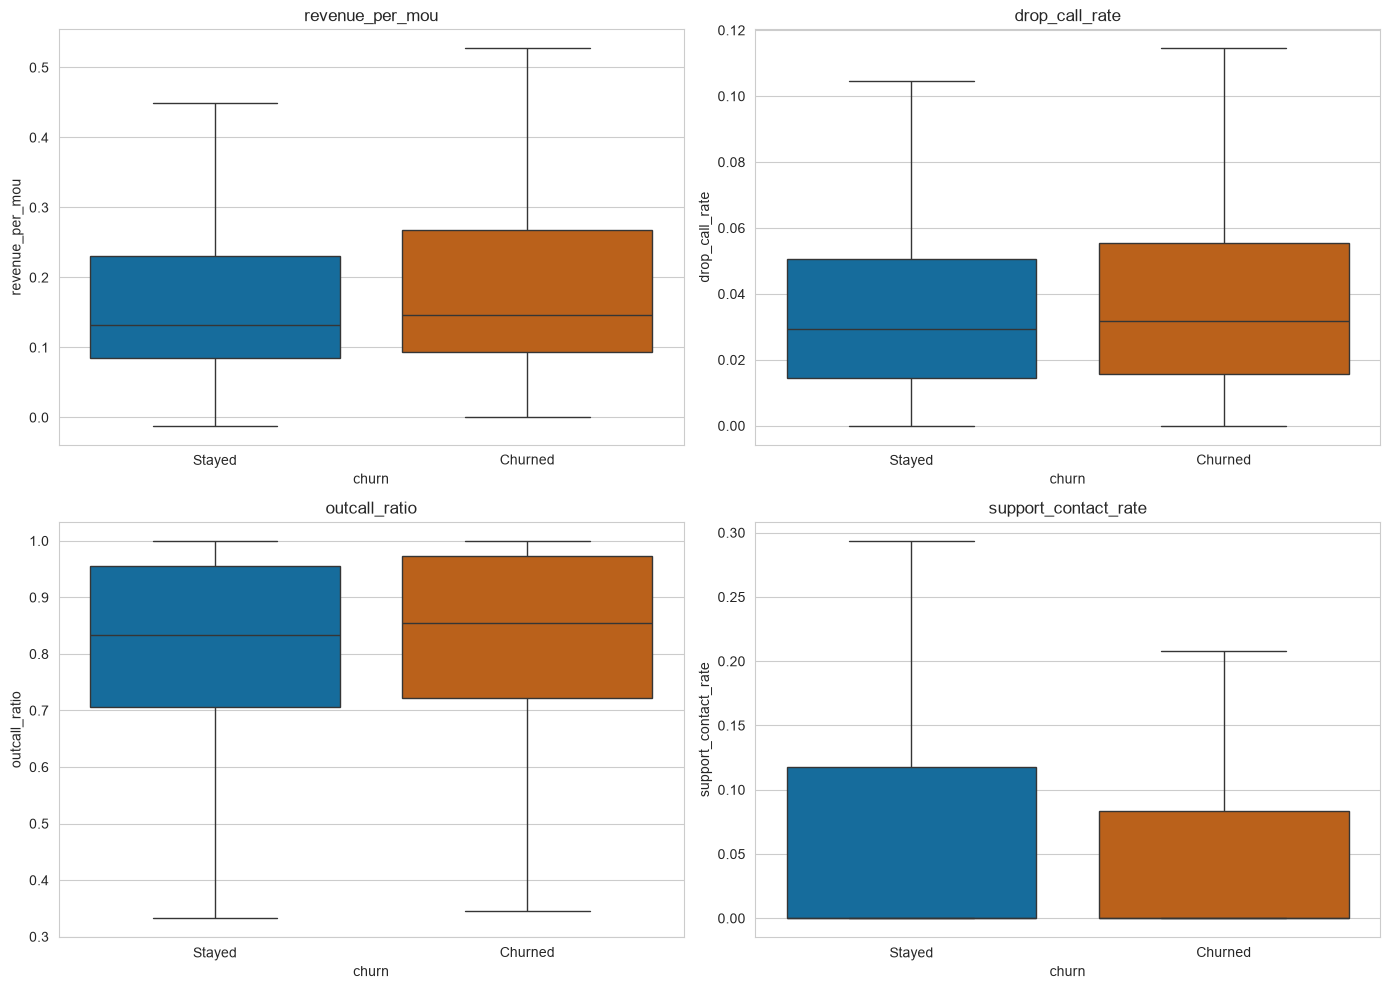

In [21]:
df_int = df.copy()
df_int['revenue_per_mou'] = df_int['revenue'] / df_int['mou'].replace(0, np.nan)
total_calls = df_int['dropvce'] + df_int['peakvce'] + df_int['opeakvce']
df_int['drop_call_rate'] = df_int['dropvce'] / total_calls.replace(0, np.nan)
df_int['outcall_ratio'] = (df_int['outcalls'] /
                           (df_int['outcalls'] + df_int['incalls']).replace(0, np.nan))
df_int['support_contact_rate'] = ((df_int['custcare'] + df_int['retcalls']) /
                                  df_int['months'].replace(0, np.nan))

interaction_cols = ['revenue_per_mou', 'drop_call_rate',
                   'outcall_ratio', 'support_contact_rate']
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()
for ax, col in zip(axes, interaction_cols):
    sb.boxplot(data=df_int, x='churn', y=col, ax=ax,
               palette=CHURN_PALETTE, showfliers=False)
    ax.set_title(col)
    ax.set_xlabel('churn')
    ax.set_xticklabels(['Stayed', 'Churned'])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/multivariate_interactions.png", dpi=150)
plt.show()

### 4.2 Interaction Insights

- **`revenue_per_mou`** (value efficiency): churners tend toward *lower*
  revenue per minute — they pay relatively more for less activity (poor plan fit).
- **`drop_call_rate`** (dropped ÷ total calls): churners show a higher failure
  rate — a direct, interpretable quality signal.
- **`outcall_ratio`** separates usage patterns but with modest effect.
- **`support_contact_rate`** (care + retention contacts per tenure month):
  higher contact intensity tracks with churn — either as cause (problems) or
  effect (save attempts).

These ratios are strong **feature-engineering candidates** (Section 6) because
they compress correlated billing/usage blocks into interpretable, lower-dimensional
signals.

## 5. Missing Data Analysis

We quantify missingness per column, visualize the **missingness pattern** with
`missingno`, reason about the missing-data mechanism (MCAR / MAR / MNAR), and
propose an **imputation strategy** for the modeling pipeline.

In [22]:
missing_count = df.isna().sum()
missing_pct = (missing_count / len(df) * 100).round(2)
missing_df = pd.DataFrame({'missing_count': missing_count,
                           'missing_pct': missing_pct})
missing_df = (missing_df[missing_df['missing_count'] > 0]
              .sort_values('missing_count', ascending=False))
missing_df

,missing_count,missing_pct
churndep,31047,43.70
age1,1244,1.75
age2,1244,1.75
changem,502,0.71
changer,502,0.71
revenue,216,0.30
overage,216,0.30
directas,216,0.30
recchrge,216,0.30
mou,216,0.30


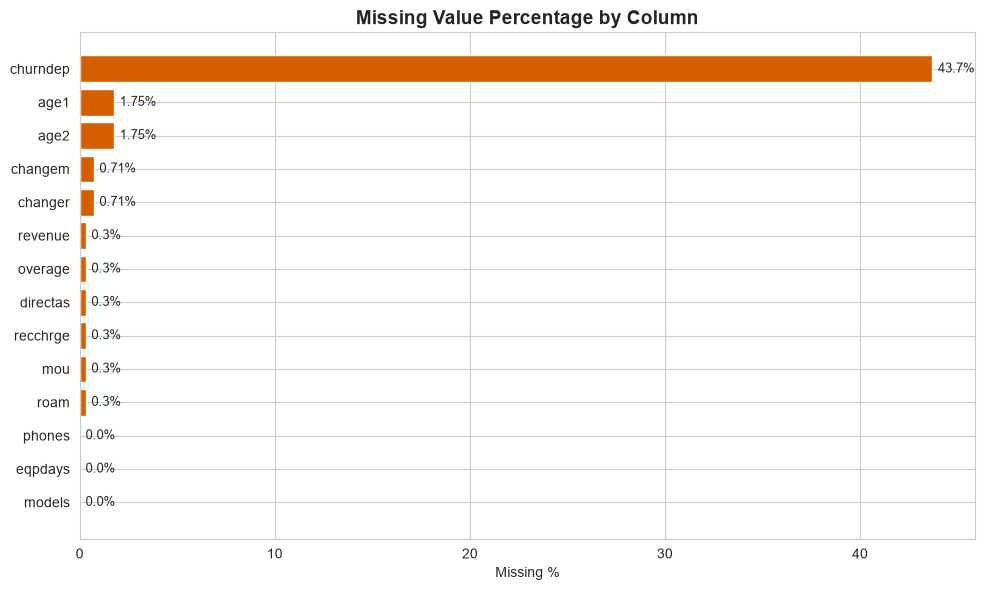

In [23]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(missing_df.index[::-1], missing_df['missing_pct'][::-1], color=CB_COLORS[1])
ax.set_title('Missing Value Percentage by Column', fontsize=14, fontweight='bold')
ax.set_xlabel('Missing %')
for i, (idx, row) in enumerate(missing_df[::-1].iterrows()):
    ax.text(row['missing_pct'] + 0.3, i, f"{row['missing_pct']}%",
            va='center', fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missing_pct_bar.png", dpi=150)
plt.show()

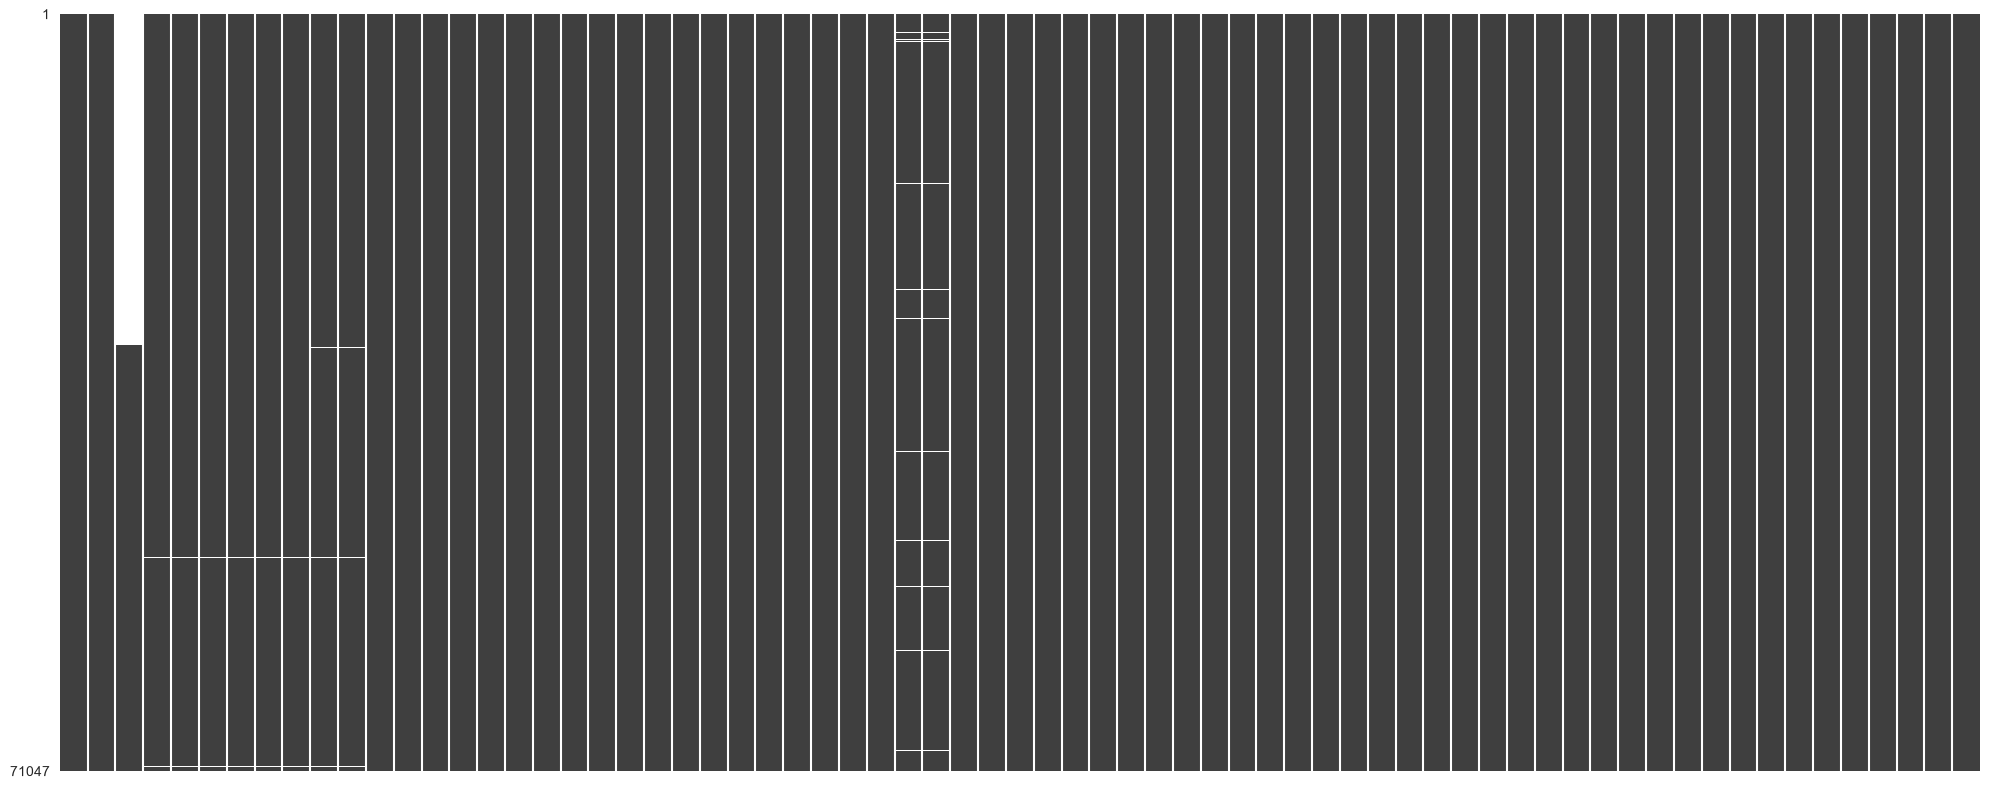

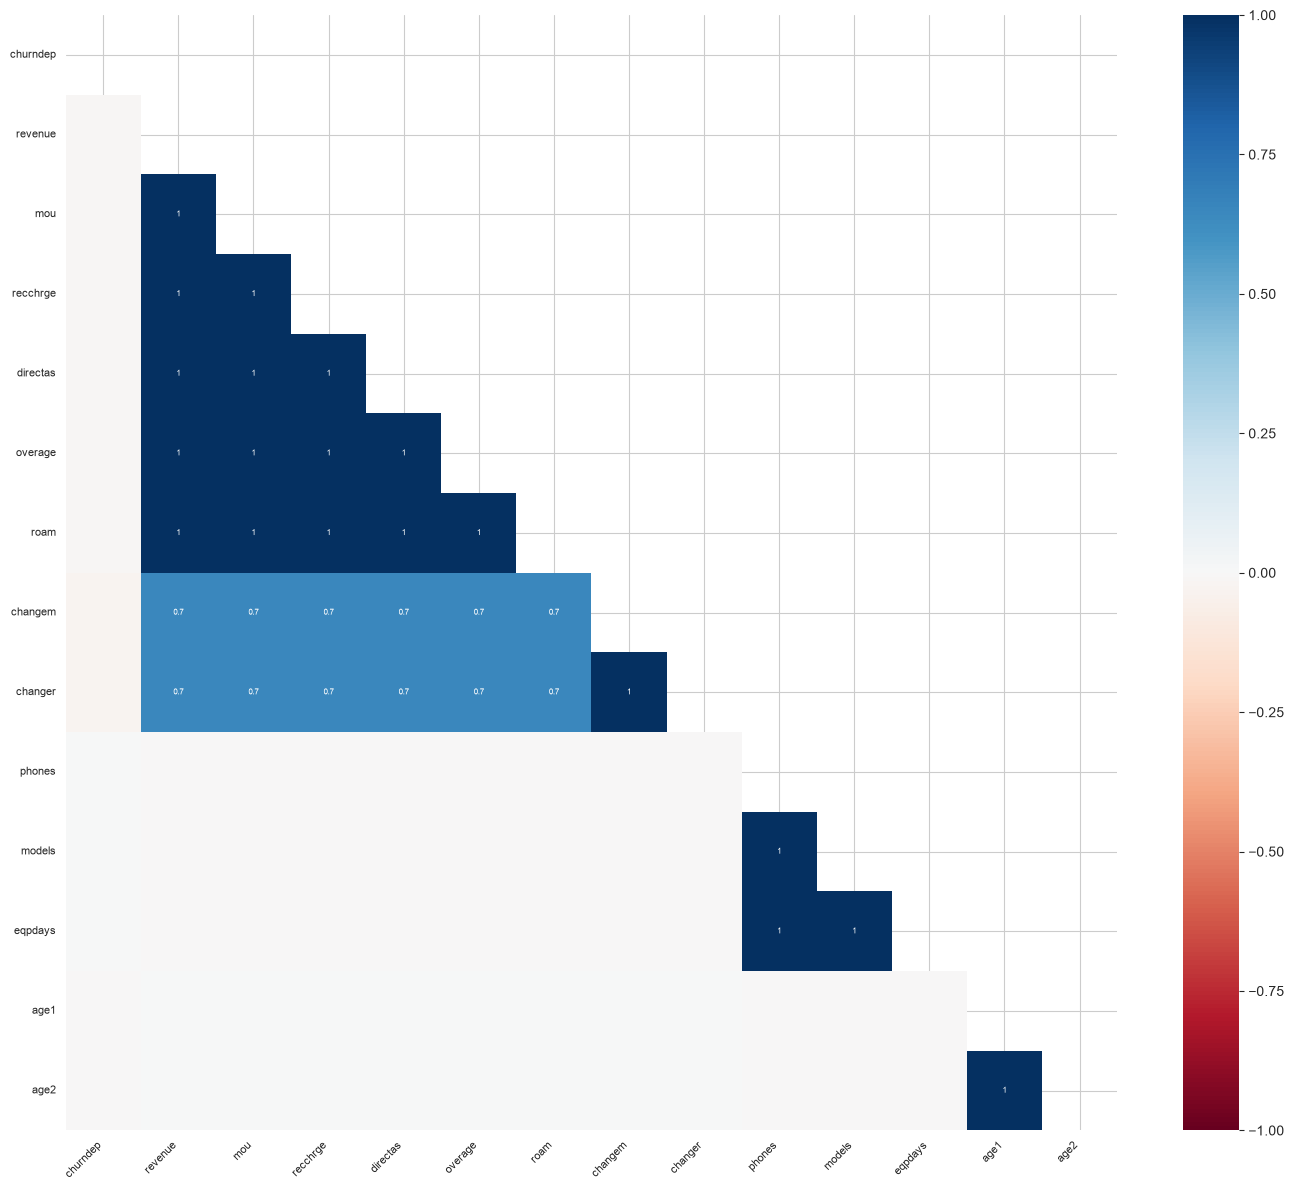

In [24]:
fig, ax = plt.subplots(figsize=(20, 8))
msno.matrix(df, ax=ax, fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missingno_matrix.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(14, 12))
msno.heatmap(df, ax=ax, fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/missingno_heatmap.png", dpi=150)
plt.show()

### 5.1 Missing-Data Reasoning (per column)

| Column | Missing | Likely Mechanism | Reasoning |
|---|---|---|---|
| `churndep` | 31,047 (43.7%) | **MNAR / structural** | Only populated for the training half (`traintest`=1). It is a *dependent/leakage* variable, not a genuine customer attribute. |
| `revenue`, `mou`, `recchrge`, `directas`, `overage`, `roam` | 216 each (0.3%) | **MCAR** | Same 216 rows missing across all six billing/usage fields — likely a batch/extract gap, unrelated to churn. |
| `changem`, `changer` | 502 each (0.7%) | **MCAR** | Same customers missing both change fields; a superset of the 216 above. |
| `phones`, `models`, `eqpdays` | 1 each | **Data entry error** | Single-row gaps; trivial to impute. |
| `age1`, `age2` | 1,244 each (1.75%) | **MAR (possible)** | Younger / privacy-conscious customers may be less likely to provide age; worth checking against `incmiss`. |

**Leakage warning:** `churndep` is essentially the *answer* for the training
set. Including it as a predictor would inflate offline metrics and fail in
production. **Drop it** (or quarantine it as an auxiliary training label only).

### 5.2 Imputation Strategy Recommendations

| Column(s) | Missing | Strategy |
|---|---|---|
| `churndep` | 43.7% | **Drop** (or keep only as auxiliary training target — leakage risk). |
| `revenue`, `mou`, `recchrge`, `directas`, `overage`, `roam` | 0.3% | **Median** imputation (skewed distributions; mean would be pulled by outliers). |
| `changem`, `changer` | 0.7% | **Median** imputation. |
| `phones`, `models`, `eqpdays` | 1 row each | **Median** imputation (negligible impact). |
| `age1`, `age2` | 1.75% | **Median** imputation, optionally stratified by `incmiss` / customer type. |

Total missing rate across the frame is low (< 0.5% of all cells once `churndep`
is excluded), so simple median imputation inside a **sklearn `Pipeline`** is
sufficient — no complex MICE/iterative imputer required for v1.

## 6. Data Quality Summary

A consolidated view of what we learned and the decisions it drives for the
modeling phase.

### 6.1 Key Findings

- **Size & balance:** 71,047 rows × 69 usable features after dropping 3
  identifier columns. Target is **moderately imbalanced** (~29% churn).
- **Dropped columns:** 3 non-informative (`Unnamed: 0`, `X`, `customer`).
  `traintest` is **kept** for now; `churndep` flagged for drop/quarantine.
- **Missing data:** only `churndep` (43.7%, structural) and a handful of
  columns at ≤1.75%. Overall non-`churndep` missing rate is < 0.5%.
- **Top churn predictors:** retention engagement (`retcall`, `retcalls`,
  `retaccpt`), tenure (`months`), call quality (`dropvce`, `unansvce`), and
  negative billing changes (`changer`, `changem`).
- **Multicollinearity:** strong blocks within billing and within usage; harmless
  for trees, problematic for unregularized linear models.
- **Outliers:** present in `revenue`/`mou`/`overage` (legitimate "whale"
  accounts) — keep, but transform/scale.

### 6.2 Feature Engineering Recommendations

| Action | Columns | Rationale |
|---|---|---|
| **Drop** | `Unnamed: 0`, `X`, `customer`, `churndep` | Non-informative or leakage. |
| **Ratios** | `revenue_per_mou`, `outcall_ratio`, `drop_call_rate`, `support_contact_rate` | Compress correlated blocks into interpretable signals (validated in §4.2). |
| **Binning** | `months` → tenure groups, `age1` → age groups, `income` → brackets | Stabilize nonlinear effects, help linear models. |
| **Interactions** | `high_value_low_tenure`, `frequent_calls_high_drops` | Capture combined risk patterns. |
| **Encoding** | OHE for low-cardinality (`occ*`, `prizm*`, `marry*`); target-encode high-cardinality | Standard sklearn `ColumnTransformer`. |
| **Keep** | `traintest` | Decide split strategy in training phase. |

See `docs/work-plan.md → Feature Engineering Plan` for the full matrix.

### 6.3 Modeling Considerations

- **Imbalanced target** → use a **stratified train/test split**, and compare
  `class_weight='balanced'` vs **SMOTE** oversampling (per work-plan Phase 3).
  Prefer **PR-AUC** over ROC-AUC for threshold selection (minority-focused).
- **Many binary features + correlated blocks** → tree ensembles
  (RandomForest, XGBoost, LightGBM, CatBoost) handle these natively;
  **Logistic Regression** needs `C` regularization / dimensionality reduction.
- **Multicollinearity** → irrelevant for trees; penalize linear models
  (L1/L2). Avoid naive feature selection that drops one of a correlated pair
  without checking business meaning.
- **Outliers / skew** → apply `RobustScaler` or log-transform to continuous
  inputs for linear models; trees are scale-invariant.
- **Leakage guard** → exclude `churndep` from every feature matrix; validate
  the pipeline on a held-out, leakage-free split before trusting metrics.

**Next step:** build `src/data` + `src/features` (Phase 2) implementing the
cleaning and engineering decisions above, then the training pipeline (Phase 3).

## 7. Save Cleaned Dataset

Export the cleaned DataFrame (non-informative columns dropped, ready for
pipeline processing) to `data/processed/cell2cell_cleaned.csv` for use by
the training and evaluation notebooks.

In [25]:
import os

# Ensure processed directory exists
processed_dir = os.path.join(ROOT, 'data', 'processed')
os.makedirs(processed_dir, exist_ok=True)

# Save cleaned dataset
# `df` already has non-informative columns (Unnamed: 0, X, customer) dropped
# from cell 2. This is the cleaned, EDA-ready DataFrame.
save_path = os.path.join(processed_dir, 'cell2cell_cleaned.csv')
df.to_csv(save_path, index=False)
print(f"Cleaned dataset saved to: {save_path}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Cleaned dataset saved to: /Users/yusef/projects/portfolio/customer-churn-prediction/data/processed/cell2cell_cleaned.csv
Shape: 71,047 rows x 69 columns
